In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("public_transport_delays.csv")

# Display first 5 rows
df.head()

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1


In [2]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Total records
print("Total Rows:", df.shape[0])

# Total features
print("Total Columns:", df.shape[1])

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (2000, 24)
Total Rows: 2000
Total Columns: 24

Column Names:
['trip_id', 'date', 'time', 'transport_type', 'route_id', 'origin_station', 'destination_station', 'scheduled_departure', 'scheduled_arrival', 'actual_departure_delay_min', 'actual_arrival_delay_min', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'delayed']


In [3]:
# Check data types
print("DATA TYPES")
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:",
      df.isnull().sum().sum())

DATA TYPES
trip_id                        object
date                           object
time                           object
transport_type                 object
route_id                       object
origin_station                 object
destination_station            object
scheduled_departure            object
scheduled_arrival              object
actual_departure_delay_min      int64
actual_arrival_delay_min        int64
weather_condition              object
temperature_C                 float64
humidity_percent                int64
wind_speed_kmh                  int64
precipitation_mm              float64
event_type                     object
event_attendance_est            int64
traffic_congestion_index        int64
holiday                         int64
peak_hour                       int64
weekday                         int64
season                         object
delayed                         int64
dtype: object

MISSING VALUES
trip_id                          0
date        

In [4]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate trip IDs
print("Duplicate Trip IDs:", df["trip_id"].duplicated().sum())

Duplicate Rows: 0
Duplicate Trip IDs: 0


In [5]:
# Target variable
target = "actual_arrival_delay_min"

# Statistical information
print("Target Variable Analysis")
print(df[target].describe())

# Check unique delay values
print("\nUnique Values:", df[target].nunique())

# Check minimum and maximum delay
print("\nMinimum Delay:", df[target].min())
print("Maximum Delay:", df[target].max())

# Check missing values
print("\nMissing Values:", df[target].isnull().sum())

Target Variable Analysis
count    2000.000000
mean       13.318000
std         9.289727
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64

Unique Values: 33

Minimum Delay: -3
Maximum Delay: 29

Missing Values: 0


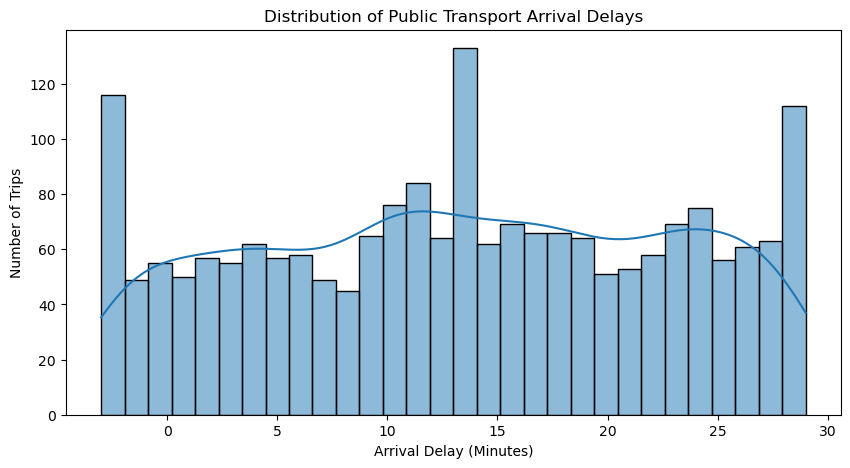

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df[target].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Public Transport Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Trips")

plt.show()

In [7]:
# Average delay by weather condition

weather_analysis = df.groupby(
    "weather_condition"
)["actual_arrival_delay_min"].mean().sort_values(
    ascending=False
)

print(weather_analysis)

weather_condition
Rain      13.623053
Snow      13.533528
Clear     13.501458
Storm     13.287834
Cloudy    13.073846
Fog       12.879154
Name: actual_arrival_delay_min, dtype: float64


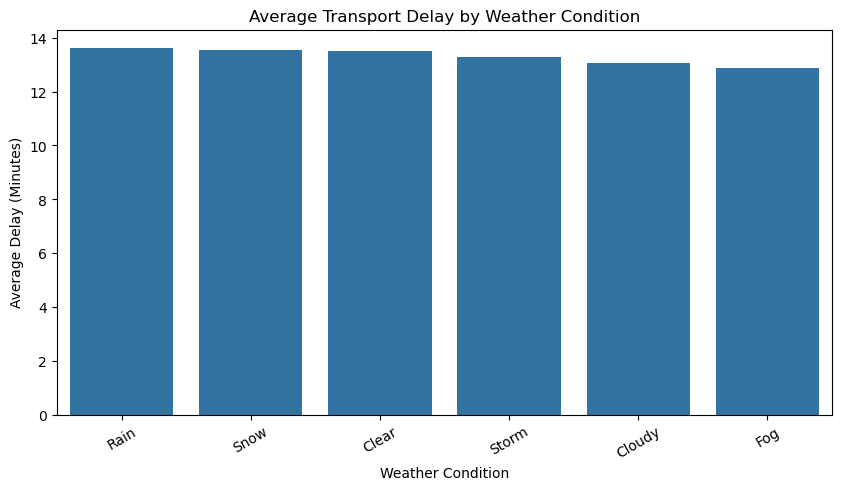

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weather_analysis.index,
    y=weather_analysis.values
)

plt.title("Average Transport Delay by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [9]:
event_analysis = df.groupby(
    "event_type"
)["actual_arrival_delay_min"].agg(
    ["mean", "median", "count"]
).sort_values(
    by="mean",
    ascending=False
)

print(event_analysis)

                 mean  median  count
event_type                          
Protest     13.895349    13.0     86
Parade      13.619048    14.0    105
Concert     12.832512    13.0    203
Sports      12.820755    13.0    212
Festival    12.769231    13.0    221


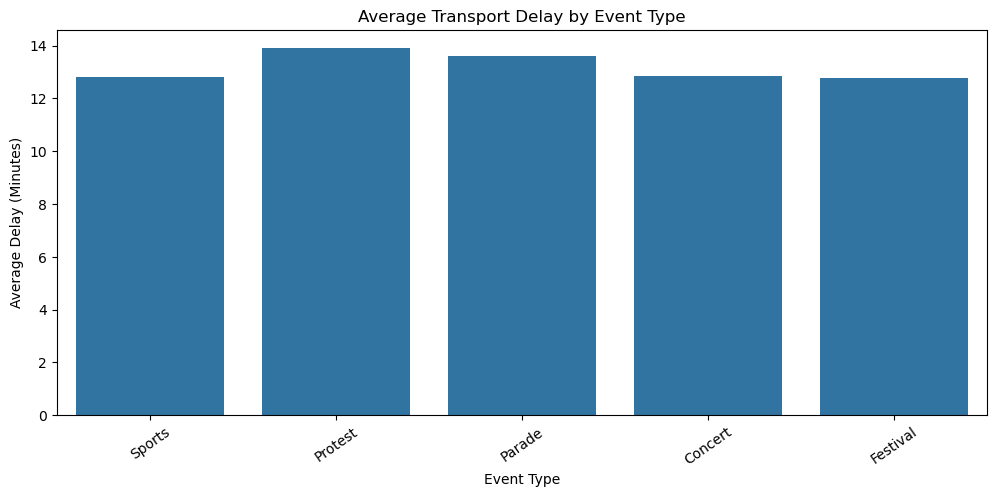

In [10]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x="event_type",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=35)

plt.show()

In [11]:
# Average delay by traffic congestion

traffic_analysis = df.groupby(
    "traffic_congestion_index"
)["actual_arrival_delay_min"].mean()

print(traffic_analysis)

traffic_congestion_index
0     14.894737
1     13.714286
2     13.173913
3     12.913043
4     14.260870
        ...    
95    13.400000
96    12.000000
97    16.857143
98    10.176471
99    11.428571
Name: actual_arrival_delay_min, Length: 100, dtype: float64


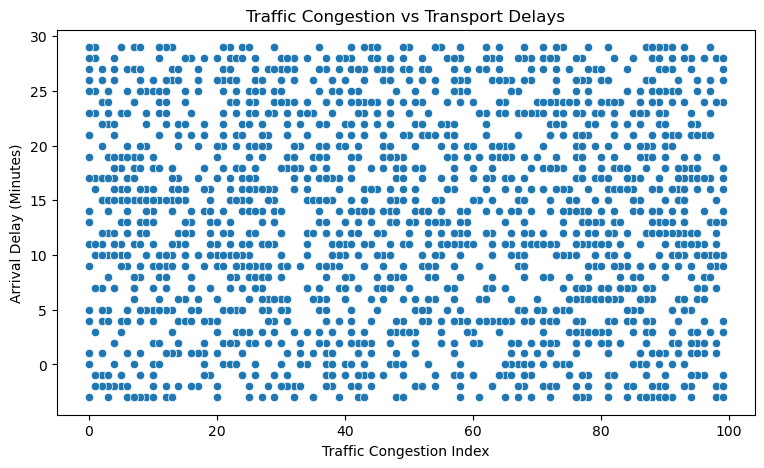

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="traffic_congestion_index",
    y="actual_arrival_delay_min"
)

plt.title("Traffic Congestion vs Transport Delays")
plt.xlabel("Traffic Congestion Index")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()

In [13]:
# Average delay during peak and non-peak hours

peak_analysis = df.groupby("peak_hour")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"])

print(peak_analysis)

                mean  median  count
peak_hour                          
0          13.302198    13.0   1456
1          13.360294    14.0    544


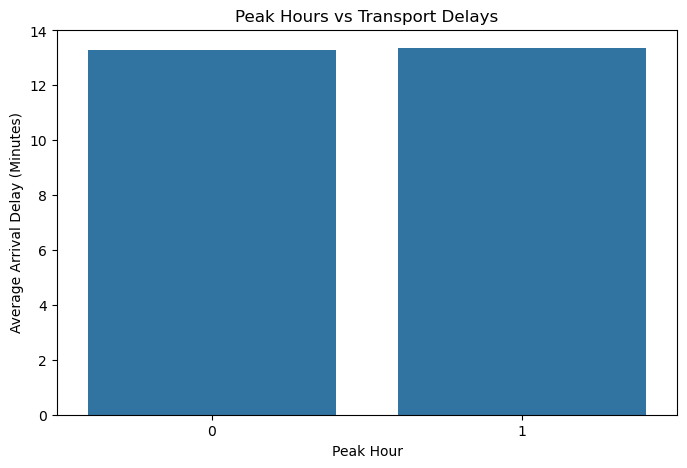

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="peak_hour",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Peak Hours vs Transport Delays")
plt.xlabel("Peak Hour")
plt.ylabel("Average Arrival Delay (Minutes)")

plt.show()

In [15]:
# Average delay by weekday

weekday_analysis = df.groupby("weekday")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"]).sort_values(
    by="mean",
    ascending=False
)

print(weekday_analysis)

              mean  median  count
weekday                          
4        14.305556    15.0    288
0        14.041667    14.0    288
5        13.732639    14.5    288
1        13.118056    13.0    288
2        12.888889    13.0    288
6        12.797794    12.0    272
3        12.312500    12.0    288


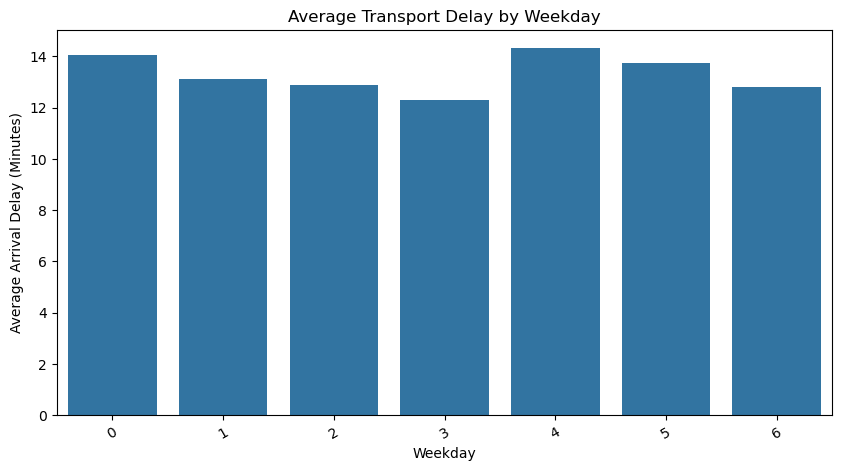

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weekday",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [17]:
weekday_analysis = df.groupby("weekday")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"]).sort_values(
    by="mean", ascending=False
)

print(weekday_analysis)

              mean  median  count
weekday                          
4        14.305556    15.0    288
0        14.041667    14.0    288
5        13.732639    14.5    288
1        13.118056    13.0    288
2        12.888889    13.0    288
6        12.797794    12.0    272
3        12.312500    12.0    288


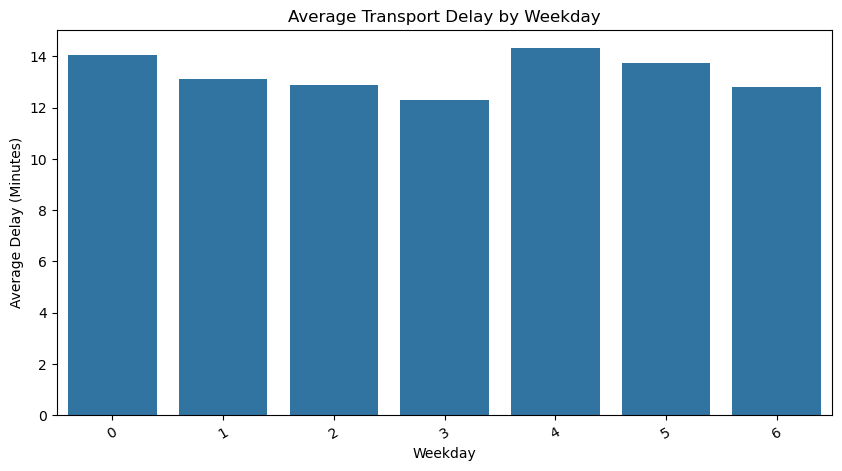

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weekday",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [19]:
temperature_analysis = df.groupby(
    pd.cut(df["temperature_C"], bins=5)
)["actual_arrival_delay_min"].mean()

print(temperature_analysis)

temperature_C
(-5.04, 3.0]    13.859375
(3.0, 11.0]     13.235714
(11.0, 19.0]    13.466334
(19.0, 27.0]    13.481865
(27.0, 35.0]    12.594132
Name: actual_arrival_delay_min, dtype: float64


C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_13252\3713428725.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temperature_analysis = df.groupby(


In [20]:
rain_analysis = df.groupby(
    pd.cut(df["precipitation_mm"], bins=5),
    observed=True
)["actual_arrival_delay_min"].mean()

print(rain_analysis)

precipitation_mm
(-0.02, 4.0]    13.461722
(4.0, 8.0]      13.645933
(8.0, 12.0]     12.276923
(12.0, 16.0]    13.573604
(16.0, 20.0]    13.602632
Name: actual_arrival_delay_min, dtype: float64


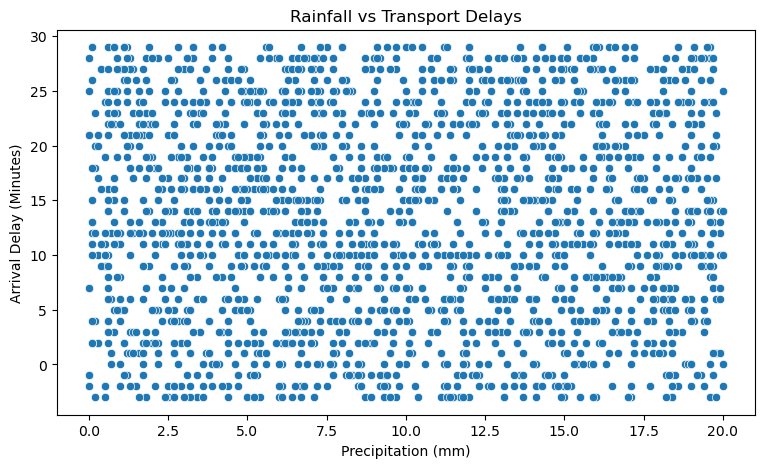

In [21]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="precipitation_mm",
    y="actual_arrival_delay_min"
)

plt.title("Rainfall vs Transport Delays")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()

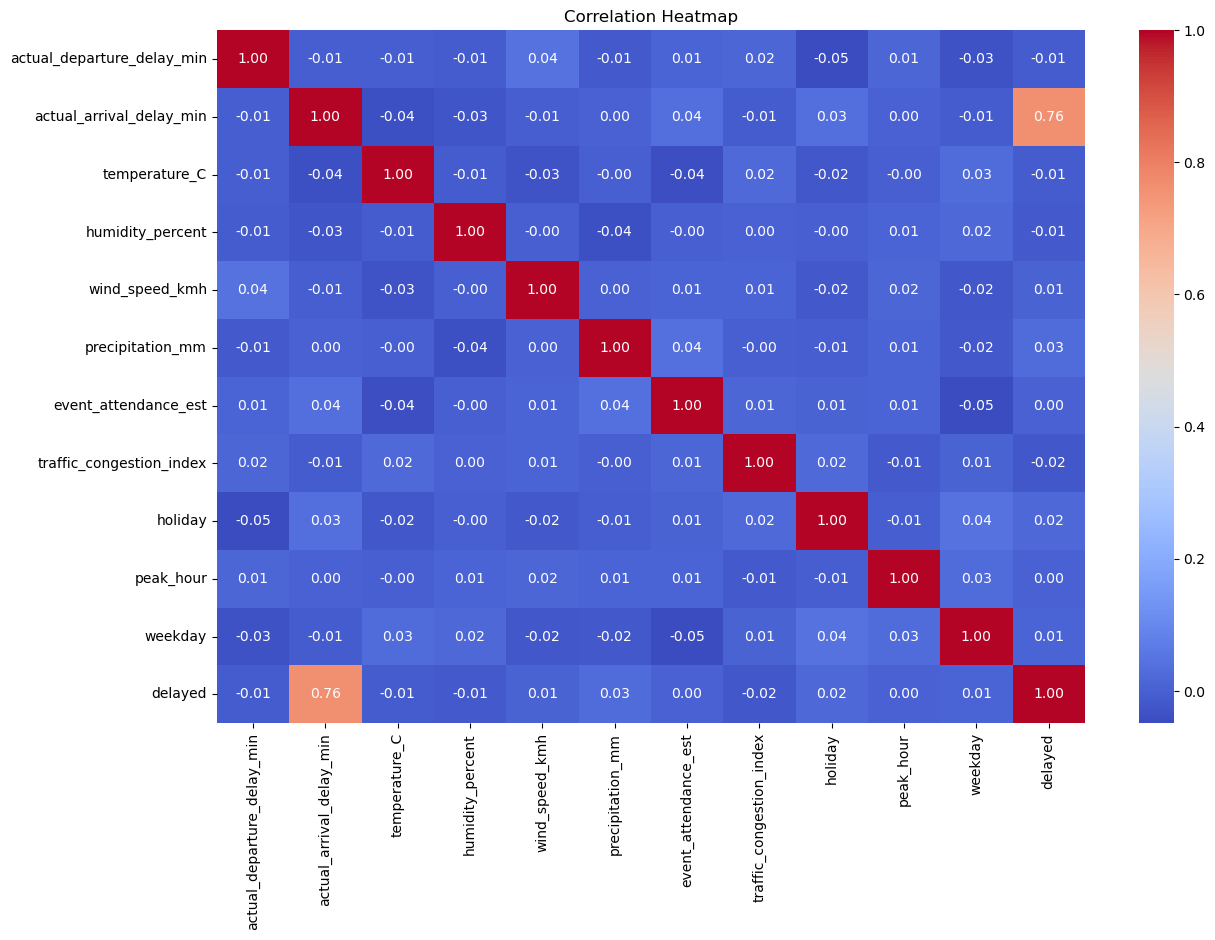

In [22]:
plt.figure(figsize=(14, 9))

correlation = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [23]:
target_corr = correlation[
    "actual_arrival_delay_min"
].sort_values(ascending=False)

print(target_corr)

actual_arrival_delay_min      1.000000
delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
precipitation_mm              0.001106
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
humidity_percent             -0.027705
temperature_C                -0.039944
Name: actual_arrival_delay_min, dtype: float64


In [24]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Missing Values:")
print(missing)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
event_type    1173
dtype: int64

Total Missing Values: 1173


In [25]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate trip IDs:", df["trip_id"].duplicated().sum())

Duplicate rows: 0
Duplicate trip IDs: 0


In [26]:
print(df.dtypes)

trip_id                        object
date                           object
time                           object
transport_type                 object
route_id                       object
origin_station                 object
destination_station            object
scheduled_departure            object
scheduled_arrival              object
actual_departure_delay_min      int64
actual_arrival_delay_min        int64
weather_condition              object
temperature_C                 float64
humidity_percent                int64
wind_speed_kmh                  int64
precipitation_mm              float64
event_type                     object
event_attendance_est            int64
traffic_congestion_index        int64
holiday                         int64
peak_hour                       int64
weekday                         int64
season                         object
delayed                         int64
dtype: object


In [27]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["scheduled_departure"] = pd.to_datetime(
    df["scheduled_departure"], errors="coerce"
)

df["scheduled_arrival"] = pd.to_datetime(
    df["scheduled_arrival"], errors="coerce"
)

print(df.dtypes)

C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_13252\1498974737.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["scheduled_departure"] = pd.to_datetime(
C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_13252\1498974737.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["scheduled_arrival"] = pd.to_datetime(


trip_id                               object
date                          datetime64[ns]
time                                  object
transport_type                        object
route_id                              object
origin_station                        object
destination_station                   object
scheduled_departure           datetime64[ns]
scheduled_arrival             datetime64[ns]
actual_departure_delay_min             int64
actual_arrival_delay_min               int64
weather_condition                     object
temperature_C                        float64
humidity_percent                       int64
wind_speed_kmh                         int64
precipitation_mm                     float64
event_type                            object
event_attendance_est                   int64
traffic_congestion_index               int64
holiday                                int64
peak_hour                              int64
weekday                                int64
season    

In [28]:
print(df["scheduled_departure"].head())
print(df["scheduled_arrival"].head())

0   2026-11-10 05:02:00
1   2026-11-10 05:16:00
2   2026-11-10 05:33:00
3   2026-11-10 05:49:00
4   2026-11-10 06:00:00
Name: scheduled_departure, dtype: datetime64[ns]
0   2026-11-10 05:55:00
1   2026-11-10 05:55:00
2   2026-11-10 06:17:00
3   2026-11-10 06:08:00
4   2026-11-10 06:35:00
Name: scheduled_arrival, dtype: datetime64[ns]


In [29]:
print("Invalid dates:", df["date"].isna().sum())

print("Invalid departures:",
      df["scheduled_departure"].isna().sum())

print("Invalid arrivals:",
      df["scheduled_arrival"].isna().sum())

Invalid dates: 0
Invalid departures: 0
Invalid arrivals: 0


In [30]:
df.to_csv(
    "public_transport_delays_cleaned.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [31]:
df["departure_hour"] = df["scheduled_departure"].dt.hour

df["departure_day"] = df["date"].dt.day

df["departure_month"] = df["date"].dt.month

df["is_weekend"] = (
    df["date"].dt.dayofweek >= 5
).astype(int)

print(df[[
    "scheduled_departure",
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend"
]].head(10))

  scheduled_departure  departure_hour  departure_day  departure_month  \
0 2026-11-10 05:02:00               5              1                1   
1 2026-11-10 05:16:00               5              1                1   
2 2026-11-10 05:33:00               5              1                1   
3 2026-11-10 05:49:00               5              1                1   
4 2026-11-10 06:00:00               6              1                1   
5 2026-11-10 06:15:00               6              1                1   
6 2026-11-10 06:34:00               6              1                1   
7 2026-11-10 06:47:00               6              1                1   
8 2026-11-10 07:01:00               7              1                1   
9 2026-11-10 07:17:00               7              1                1   

   is_weekend  
0           1  
1           1  
2           1  
3           1  
4           1  
5           1  
6           1  
7           1  
8           1  
9           1  


In [32]:
def classify_rush_hour(hour):

    if 7 <= hour <= 10:
        return "Morning Rush"

    elif 17 <= hour <= 20:
        return "Evening Rush"

    else:
        return "Non-Rush"


df["rush_hour_category"] = df["departure_hour"].apply(
    classify_rush_hour
)

print(df["rush_hour_category"].value_counts())

rush_hour_category
Non-Rush        1328
Morning Rush     336
Evening Rush     336
Name: count, dtype: int64


In [33]:
print(df[[
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend",
    "rush_hour_category"
]].head(10))

   departure_hour  departure_day  departure_month  is_weekend  \
0               5              1                1           1   
1               5              1                1           1   
2               5              1                1           1   
3               5              1                1           1   
4               6              1                1           1   
5               6              1                1           1   
6               6              1                1           1   
7               6              1                1           1   
8               7              1                1           1   
9               7              1                1           1   

  rush_hour_category  
0           Non-Rush  
1           Non-Rush  
2           Non-Rush  
3           Non-Rush  
4           Non-Rush  
5           Non-Rush  
6           Non-Rush  
7           Non-Rush  
8       Morning Rush  
9       Morning Rush  


In [34]:
rush_analysis = df.groupby(
    "rush_hour_category"
)["actual_arrival_delay_min"].agg(
    ["mean", "median", "count"]
)

print(rush_analysis)

                         mean  median  count
rush_hour_category                          
Evening Rush        12.952381    13.0    336
Morning Rush        13.845238    14.0    336
Non-Rush            13.277108    13.0   1328


In [35]:
# Define target variable
target = "actual_arrival_delay_min"

# Columns we should exclude
drop_columns = [
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
    "delayed"
]

# Separate features and target
X = df.drop(columns=drop_columns)

y = df[target]

# Display results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Features shape: (2000, 21)
Target shape: (2000,)

Feature columns:
['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend', 'rush_hour_category']

Target variable:
actual_arrival_delay_min


In [36]:
# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nTotal categorical:", len(categorical_features))
print("Total numerical:", len(numerical_features))

Categorical Features:
['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season', 'rush_hour_category']

Numerical Features:
['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend']

Total categorical: 8
Total numerical: 13


In [37]:
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Unique dates:", df["date"].nunique())

First date: 2023-01-01 00:00:00
Last date: 2023-01-22 00:00:00
Unique dates: 22


In [38]:
# Sort records chronologically
df_sorted = df.sort_values("date").copy()

# 80% training, 20% testing
split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index]
test_df = df_sorted.iloc[split_index:]

# Separate features and target
X_train = train_df[X.columns]
X_test = test_df[X.columns]

y_train = train_df[target]
y_test = test_df[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [40]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [41]:
y_pred_linear = linear_model.predict(X_test)

print("Actual values:", y_test.head(10).values)

print("\nPredicted values:", y_pred_linear[:10])

Actual values: [27  4 21 16 10 -3 -2 28 10  0]

Predicted values: [11.71080924 14.31384918 16.59599431 11.51581367 12.63461707 11.52232404
 14.76366611 13.58368213 11.93904333 13.45886172]


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred_linear)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2 = r2_score(y_test, y_pred_linear)

print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 8.418
RMSE: 9.78
R2 Score: -0.06


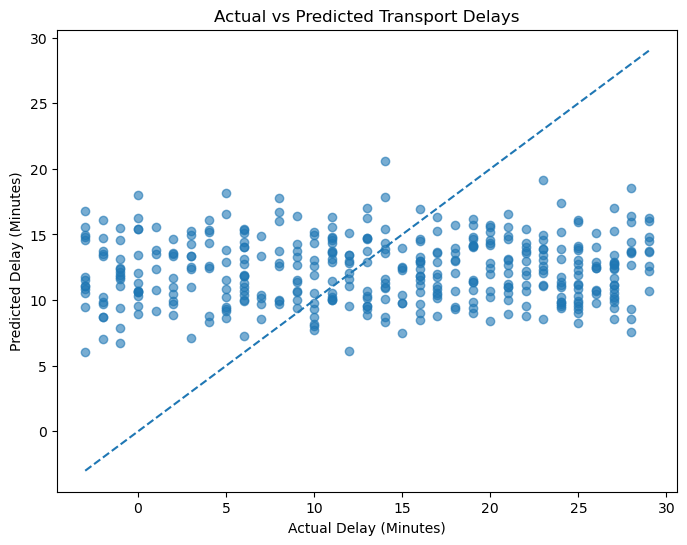

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delay (Minutes)")
plt.ylabel("Predicted Delay (Minutes)")
plt.title("Actual vs Predicted Transport Delays")

plt.show()

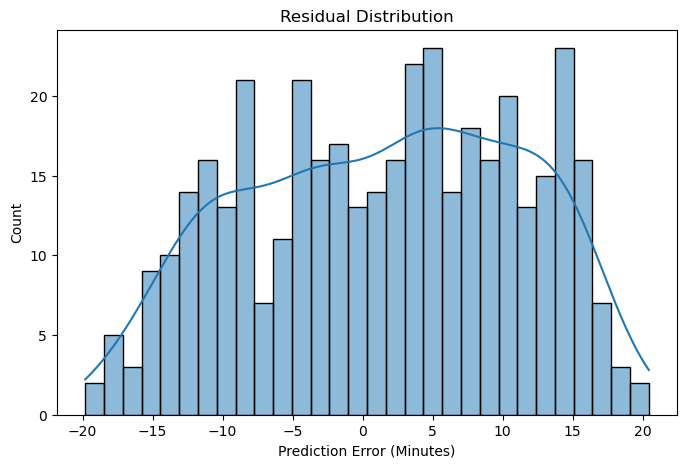

In [44]:
residuals = y_test - y_pred_linear

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error (Minutes)")
plt.show()

In [45]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [46]:
# Generate Random Forest predictions

y_pred_rf = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("Actual values:", y_test.head(10).values)
print("Predicted values:", y_pred_rf[:10])

Predictions generated successfully!
Actual values: [27  4 21 16 10 -3 -2 28 10  0]
Predicted values: [12.86803616 14.01164187 12.26623303 12.49963517 12.83379012 14.70255308
 13.67250969 12.60149335 13.08074568 13.13177144]


In [47]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST PERFORMANCE")
print("--------------------------")
print("MAE:", round(mae_rf, 3))
print("RMSE:", round(rmse_rf, 3))
print("R2 Score:", round(r2_rf, 3))

RANDOM FOREST PERFORMANCE
--------------------------
MAE: 8.227
RMSE: 9.532
R2 Score: -0.007


In [48]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [49]:
from xgboost import XGBRegressor

print("XGBoost installed successfully!")

XGBoost installed successfully!


In [50]:
from xgboost import XGBRegressor

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective="reg:squarederror"
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [51]:
y_pred_xgb = xgb_model.predict(X_test)

print("Actual:", y_test.head(10).values)
print("Predicted:", y_pred_xgb[:10])

Actual: [27  4 21 16 10 -3 -2 28 10  0]
Predicted: [12.664968 14.781757 15.560923 12.569046 10.219308 13.870145 14.176814
 12.839012 12.621655 13.451469]


In [52]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBOOST PERFORMANCE")
print("--------------------")
print("MAE:", round(mae_xgb, 3))
print("RMSE:", round(rmse_xgb, 3))
print("R2 Score:", round(r2_xgb, 3))

XGBOOST PERFORMANCE
--------------------
MAE: 8.263
RMSE: 9.569
R2 Score: -0.015


               Model       MAE      RMSE  R2 Score
0  Linear Regression  8.418188  9.779578 -0.060336
1      Random Forest  8.227377  9.532134 -0.007357
2            XGBoost  8.263261  9.568815 -0.015125


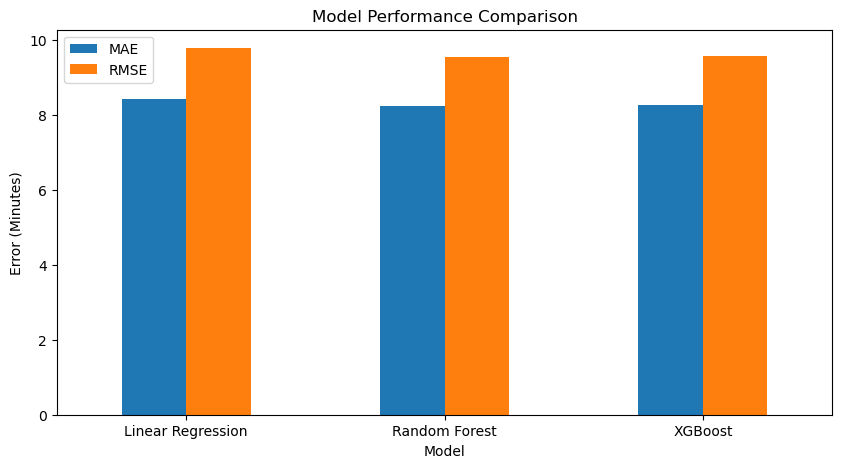

In [53]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [mae, mae_rf, mae_xgb],
    "RMSE": [rmse, rmse_rf, rmse_xgb],
    "R2 Score": [r2, r2_rf, r2_xgb]
})

print(results)

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error (Minutes)")
plt.xticks(rotation=0)
plt.show()

In [54]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MAE:",
      mean_absolute_error(y_test, baseline_predictions))

print("BASELINE R2:",
      r2_score(y_test, baseline_predictions))

BASELINE MAE: 8.212256250000001
BASELINE R2: -0.002594449182478753


In [55]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MAE:",
      mean_absolute_error(y_test, baseline_predictions))

print("BASELINE R2:",
      r2_score(y_test, baseline_predictions))

BASELINE MAE: 8.212256250000001
BASELINE R2: -0.002594449182478753


In [56]:
print("TRAINING TARGET STATISTICS")
print(y_train.describe())

print("\nTESTING TARGET STATISTICS")
print(y_test.describe())

print("\nTRAINING MEAN:", y_train.mean())
print("TESTING MEAN:", y_test.mean())

print("\nTRAINING STANDARD DEVIATION:", y_train.std())
print("TESTING STANDARD DEVIATION:", y_test.std())

TRAINING TARGET STATISTICS
count    1600.000000
mean       13.221250
std         9.234546
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64

TESTING TARGET STATISTICS
count    400.000000
mean      13.705000
std        9.509155
min       -3.000000
25%        6.000000
50%       14.000000
75%       22.000000
max       29.000000
Name: actual_arrival_delay_min, dtype: float64

TRAINING MEAN: 13.22125
TESTING MEAN: 13.705

TRAINING STANDARD DEVIATION: 9.234546359542609
TESTING STANDARD DEVIATION: 9.509155329876524


In [57]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "Baseline": baseline_predictions
})

print(comparison.mean().round(2))

Actual               13.70
Linear Regression    12.27
Random Forest        12.91
XGBoost              12.80
Baseline             13.22
dtype: float64


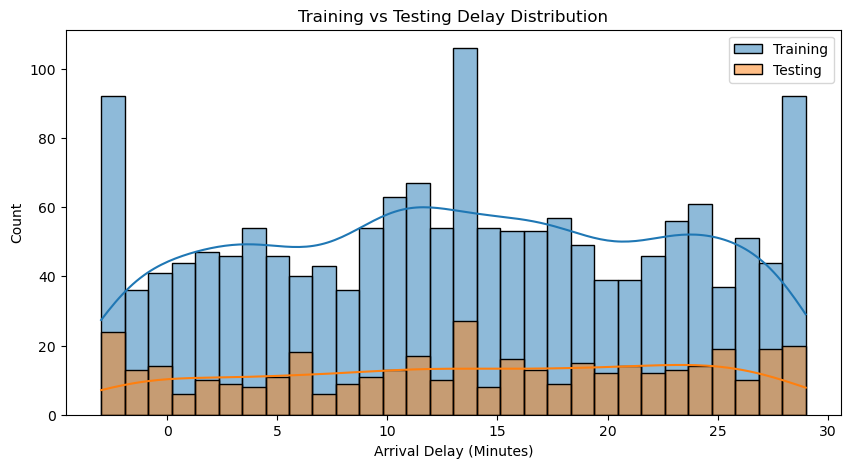

In [58]:
plt.figure(figsize=(10, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True,
    label="Training",
    alpha=0.5
)

sns.histplot(
    y_test,
    bins=30,
    kde=True,
    label="Testing",
    alpha=0.5
)

plt.title("Training vs Testing Delay Distribution")
plt.xlabel("Arrival Delay (Minutes)")
plt.legend()
plt.show()

In [59]:
numeric_corr = df.select_dtypes(
    include="number"
).corr()

target_relationship = numeric_corr[
    "actual_arrival_delay_min"
].drop("actual_arrival_delay_min").sort_values(
    ascending=False
)

print(target_relationship)

delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
departure_day                 0.001659
precipitation_mm              0.001106
is_weekend                   -0.002647
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
departure_hour               -0.017650
humidity_percent             -0.027705
temperature_C                -0.039944
departure_month                    NaN
Name: actual_arrival_delay_min, dtype: float64


In [60]:
print(
    df[[
        "actual_departure_delay_min",
        "actual_arrival_delay_min"
    ]].corr()
)

                            actual_departure_delay_min  \
actual_departure_delay_min                    1.000000   
actual_arrival_delay_min                     -0.007161   

                            actual_arrival_delay_min  
actual_departure_delay_min                 -0.007161  
actual_arrival_delay_min                    1.000000  


In [61]:
print(
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
)

actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64


In [62]:
# Reconstruct scheduled timestamps using the actual date

df["scheduled_departure"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d") + " " +
    df["scheduled_departure"].dt.strftime("%H:%M:%S")
)

df["scheduled_arrival"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d") + " " +
    df["scheduled_arrival"].dt.strftime("%H:%M:%S")
)

print(df[[
    "date",
    "scheduled_departure",
    "scheduled_arrival"
]].head())

        date scheduled_departure   scheduled_arrival
0 2023-01-01 2023-01-01 05:02:00 2023-01-01 05:55:00
1 2023-01-01 2023-01-01 05:16:00 2023-01-01 05:55:00
2 2023-01-01 2023-01-01 05:33:00 2023-01-01 06:17:00
3 2023-01-01 2023-01-01 05:49:00 2023-01-01 06:08:00
4 2023-01-01 2023-01-01 06:00:00 2023-01-01 06:35:00


In [63]:
# Recreate time-based features

df["departure_hour"] = df["scheduled_departure"].dt.hour

df["departure_day"] = df["date"].dt.day

df["departure_month"] = df["date"].dt.month

df["is_weekend"] = (
    df["date"].dt.dayofweek >= 5
).astype(int)

print(df[[
    "date",
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend"
]].head())

        date  departure_hour  departure_day  departure_month  is_weekend
0 2023-01-01               5              1                1           1
1 2023-01-01               5              1                1           1
2 2023-01-01               5              1                1           1
3 2023-01-01               5              1                1           1
4 2023-01-01               6              1                1           1


In [64]:
def classify_rush_hour(hour):
    if 7 <= hour <= 10:
        return "Morning Rush"
    elif 17 <= hour <= 20:
        return "Evening Rush"
    else:
        return "Non-Rush"

df["rush_hour_category"] = df[
    "departure_hour"
].apply(classify_rush_hour)

print(df["rush_hour_category"].value_counts())

rush_hour_category
Non-Rush        1328
Morning Rush     336
Evening Rush     336
Name: count, dtype: int64


In [65]:
df.to_csv(
    "public_transport_delays_cleaned.csv",
    index=False
)

print("Corrected dataset saved!")

Corrected dataset saved!


In [66]:
# Define target
target = "actual_arrival_delay_min"

# Remove identifiers and unavailable prediction-time variables
drop_columns = [
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
    "delayed"
]

X = df.drop(columns=drop_columns)
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2000, 21)
Target: (2000,)


In [67]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)


Categorical: ['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season', 'rush_hour_category']
Numerical: ['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend']


In [68]:
df_sorted = df.sort_values("date").copy()

split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index]
test_df = df_sorted.iloc[split_index:]

X_train = train_df[X.columns]
X_test = test_df[X.columns]

y_train = train_df[target]
y_test = test_df[target]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1600, 21)
Testing: (400, 21)


In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline rebuilt successfully!")

Preprocessing pipeline rebuilt successfully!


In [70]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Corrected Random Forest trained!")

Corrected Random Forest trained!


In [71]:
y_pred_rf = rf_model.predict(X_test)

print("Actual:", y_test.head(10).values)
print("Predicted:", y_pred_rf[:10])

Actual: [27  4 21 16 10 -3 -2 28 10  0]
Predicted: [13.06499297 13.91478481 12.85787049 12.49695892 12.4355072  14.84459531
 13.71608971 12.76627736 12.99355782 12.8034763 ]


In [72]:
mae_rf_corrected = mean_absolute_error(
    y_test, y_pred_rf
)

rmse_rf_corrected = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf_corrected = r2_score(
    y_test, y_pred_rf
)

print("CORRECTED RANDOM FOREST PERFORMANCE")
print("-----------------------------------")
print("MAE:", round(mae_rf_corrected, 3))
print("RMSE:", round(rmse_rf_corrected, 3))
print("R2 Score:", round(r2_rf_corrected, 3))

CORRECTED RANDOM FOREST PERFORMANCE
-----------------------------------
MAE: 8.237
RMSE: 9.539
R2 Score: -0.009


In [73]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:",
      round(mean_absolute_error(y_test, baseline_pred), 3))

print("Random Forest MAE:",
      round(mae_rf_corrected, 3))

Baseline MAE: 8.212
Random Forest MAE: 8.237


In [74]:
correlations = df[numerical_features + ["actual_arrival_delay_min"]].corr()

correlations["actual_arrival_delay_min"].sort_values(
    ascending=False
)

actual_arrival_delay_min    1.000000
event_attendance_est        0.037266
holiday                     0.033584
peak_hour                   0.002784
departure_day               0.001659
precipitation_mm            0.001106
is_weekend                 -0.002647
wind_speed_kmh             -0.007649
weekday                    -0.007785
traffic_congestion_index   -0.011006
departure_hour             -0.017650
humidity_percent           -0.027705
temperature_C              -0.039944
departure_month                  NaN
Name: actual_arrival_delay_min, dtype: float64

In [75]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

for col in categorical_features:
    print(f"\n{col}")
    print(
        df.groupby(col)["actual_arrival_delay_min"]
        .mean()
        .round(2)
        .sort_values()
    )


transport_type
transport_type
Tram     12.95
Metro    13.21
Bus      13.54
Train    13.55
Name: actual_arrival_delay_min, dtype: float64

route_id
route_id
Route_10    11.81
Route_13    11.93
Route_4     12.68
Route_9     12.83
Route_3     13.07
Route_16    13.16
Route_2     13.22
Route_8     13.31
Route_11    13.34
Route_19    13.36
Route_1     13.43
Route_20    13.46
Route_17    13.47
Route_14    13.50
Route_7     13.58
Route_6     13.84
Route_5     13.87
Route_15    13.99
Route_18    14.13
Route_12    14.29
Name: actual_arrival_delay_min, dtype: float64

origin_station
origin_station
Station_5     10.30
Station_31    10.61
Station_25    10.88
Station_37    10.95
Station_34    10.97
Station_49    11.06
Station_29    11.28
Station_2     11.32
Station_43    11.40
Station_19    11.51
Station_27    11.72
Station_41    12.20
Station_46    12.32
Station_30    12.42
Station_9     12.54
Station_50    12.67
Station_8     12.67
Station_12    12.72
Station_7     12.76
Station_45    12.87
Stati

In [76]:
for col in categorical_features:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


transport_type
transport_type
Bus      525
Train    493
Tram     491
Metro    491
Name: count, dtype: int64

route_id
route_id
Route_3     114
Route_15    112
Route_13    112
Route_17    110
Route_2     110
Route_8     109
Route_12    105
Route_14    105
Route_4     104
Route_18    101
Name: count, dtype: int64

origin_station
origin_station
Station_17    55
Station_47    51
Station_32    49
Station_40    49
Station_13    49
Station_49    49
Station_28    47
Station_29    47
Station_22    46
Station_45    45
Name: count, dtype: int64

destination_station
destination_station
Station_26    56
Station_23    54
Station_42    53
Station_18    52
Station_16    51
Station_45    47
Station_14    46
Station_7     46
Station_17    44
Station_13    44
Name: count, dtype: int64

weather_condition
weather_condition
Clear     343
Snow      343
Storm     337
Fog       331
Cloudy    325
Rain      321
Name: count, dtype: int64

event_type
event_type
Festival    221
Sports      212
Concert     203
Para

In [77]:
station_analysis = df.groupby("origin_station").agg(
    average_delay=("actual_arrival_delay_min", "mean"),
    delay_std=("actual_arrival_delay_min", "std"),
    trip_count=("actual_arrival_delay_min", "count")
).sort_values("average_delay", ascending=False)

station_analysis.round(2)

,average_delay,delay_std,trip_count
origin_station,,,
Station_14,16.89,8.18,28
Station_48,16.55,9.17,44
Station_22,15.67,9.48,46
Station_26,15.39,10.06,41
Station_16,15.24,8.66,37
Station_17,15.02,8.95,55
Station_33,14.87,8.85,30
Station_40,14.84,10.03,49
Station_35,14.77,9.44,39


In [78]:
from scipy.stats import f_oneway

station_groups = [
    group["actual_arrival_delay_min"].values
    for _, group in df.groupby("origin_station")
]

f_stat, p_value = f_oneway(*station_groups)

print("ANOVA F-statistic:", round(f_stat, 3))
print("P-value:", round(p_value, 5))

ANOVA F-statistic: 1.098
P-value: 0.29848


In [79]:
print("Target standard deviation:", round(y.std(), 3))
print("Target unique values:", y.nunique())
print("Target mean:", round(y.mean(), 3))
print("Target median:", round(y.median(), 3))

Target standard deviation: 9.29
Target unique values: 33
Target mean: 13.318
Target median: 13.0


In [80]:
print("Mean:", round(y.mean(), 2))
print("Median:", round(y.median(), 2))
print("Standard deviation:", round(y.std(), 2))
print("Unique values:", y.nunique())

Mean: 13.32
Median: 13.0
Standard deviation: 9.29
Unique values: 33


In [81]:
print(
    df.corr(numeric_only=True)["actual_arrival_delay_min"]
    .sort_values(ascending=False)
)

actual_arrival_delay_min      1.000000
delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
departure_day                 0.001659
precipitation_mm              0.001106
is_weekend                   -0.002647
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
departure_hour               -0.017650
humidity_percent             -0.027705
temperature_C                -0.039944
departure_month                    NaN
Name: actual_arrival_delay_min, dtype: float64


<Axes: title={'center': 'Average Arrival Delay by Day'}, xlabel='departure_day'>

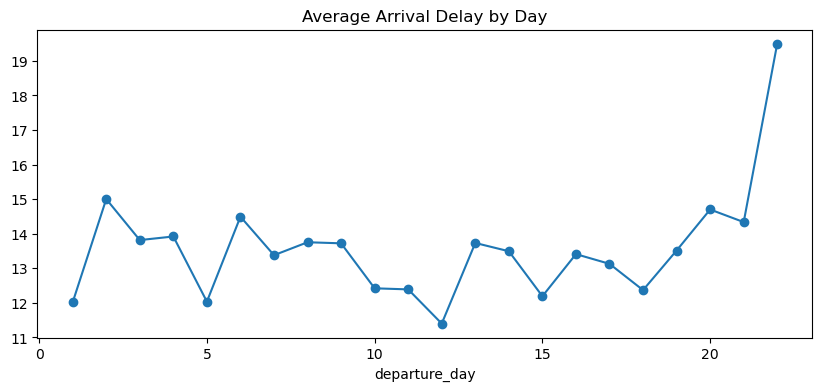

In [82]:
df.groupby("departure_day")["actual_arrival_delay_min"].mean().plot(
    figsize=(10, 4),
    marker="o",
    title="Average Arrival Delay by Day"
)


In [83]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

importance_df

,Feature,Importance
5,temperature_C,2.996171e-02
2,origin_station,2.800591e-02
16,departure_hour,2.237242e-02
10,event_attendance_est,2.085828e-02
3,destination_station,1.708261e-02
0,transport_type,1.159977e-02
1,route_id,8.040164e-03
11,traffic_congestion_index,4.953864e-03
20,rush_hour_category,4.357023e-03
8,precipitation_mm,2.003565e-03


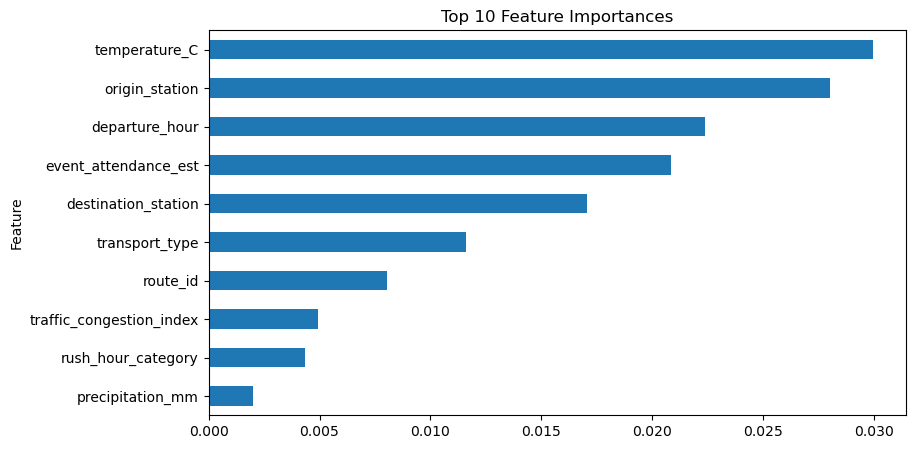

In [84]:
importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 5),
    legend=False,
    title="Top 10 Feature Importances"
)

plt.gca().invert_yaxis()
plt.show()

In [85]:
import matplotlib.pyplot as plt

In [86]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

gb_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])

gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

print("Gradient Boosting MAE:",
      round(mean_absolute_error(y_test, gb_pred), 3))
print("Gradient Boosting R2:",
      round(r2_score(y_test, gb_pred), 3))

Gradient Boosting MAE: 8.314
Gradient Boosting R2: -0.068


In [87]:
df[["date", "actual_arrival_delay_min"]].head(15)

,date,actual_arrival_delay_min
0,2023-01-01,3
1,2023-01-01,9
2,2023-01-01,0
3,2023-01-01,10
4,2023-01-01,14
5,2023-01-01,4
6,2023-01-01,28
7,2023-01-01,23
8,2023-01-01,19
9,2023-01-01,3


In [88]:
daily_delay = df.groupby("date")["actual_arrival_delay_min"].agg(
    ["mean", "std", "count"]
)

display(daily_delay.head(10))
print("Number of unique dates:", df["date"].nunique())

,mean,std,count
date,,,
2023-01-01,12.013158,9.439623,76
2023-01-02,15.000000,8.717798,96
2023-01-03,13.812500,8.879678,96
2023-01-04,13.916667,8.702893,96
2023-01-05,12.031250,9.399276,96
2023-01-06,14.489583,9.340342,96
2023-01-07,13.375000,9.692374,96
2023-01-08,13.750000,8.788749,96
2023-01-09,13.718750,9.556153,96


Number of unique dates: 22


In [89]:
print(
    df[["actual_departure_delay_min", "actual_arrival_delay_min"]]
    .corr()
)

                            actual_departure_delay_min  \
actual_departure_delay_min                    1.000000   
actual_arrival_delay_min                     -0.007161   

                            actual_arrival_delay_min  
actual_departure_delay_min                 -0.007161  
actual_arrival_delay_min                    1.000000  


In [90]:
df["scheduled_duration_min"] = (
    df["scheduled_arrival"] - df["scheduled_departure"]
).dt.total_seconds() / 60

print(
    df[["scheduled_duration_min", "actual_arrival_delay_min"]]
    .corr()
)


                          scheduled_duration_min  actual_arrival_delay_min
scheduled_duration_min                  1.000000                  0.035779
actual_arrival_delay_min                0.035779                  1.000000


In [91]:
df.groupby("departure_hour")["actual_arrival_delay_min"].agg(
    ["mean", "std", "count"]
).round(2)

,mean,std,count
departure_hour,,,
0,12.05,8.60,84
1,14.50,9.48,80
2,14.66,8.55,80
3,14.52,10.03,80
4,11.20,8.79,80
5,12.95,9.49,84
6,11.87,10.16,84
7,13.88,9.06,84
8,14.39,8.84,84


In [92]:
print(
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
)

actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64


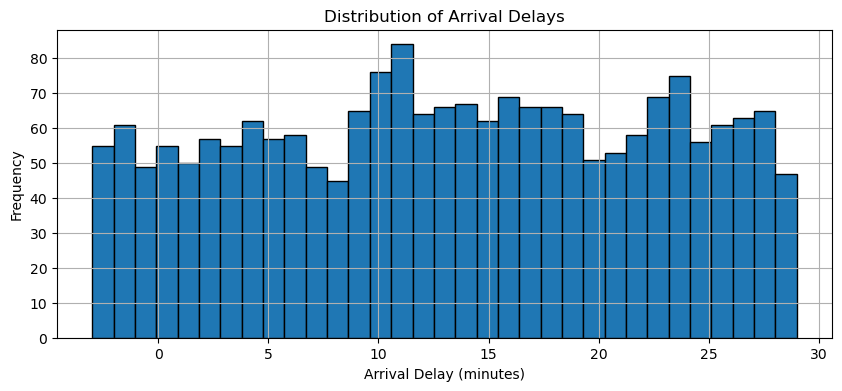

In [93]:
plt.figure(figsize=(10, 4))
df["actual_arrival_delay_min"].hist(bins=33, edgecolor="black")
plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.show()

In [94]:
from sklearn.feature_selection import mutual_info_regression

X_mi = X.copy()

for col in categorical_features:
    X_mi[col] = X_mi[col].astype("category").cat.codes

mi_scores = mutual_info_regression(
    X_mi, y, random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X_mi.columns,
    "Mutual Information": mi_scores
}).sort_values("Mutual Information", ascending=False)

display(mi_df)

,Feature,Mutual Information
10,event_attendance_est,0.027924
2,origin_station,0.013707
17,departure_day,0.010637
6,humidity_percent,0.010564
12,holiday,0.000362
13,peak_hour,0.000037
19,is_weekend,0.000000
18,departure_month,0.000000
16,departure_hour,0.000000
15,season,0.000000


In [95]:
from sklearn.utils import shuffle

y_shuffled = shuffle(y, random_state=42)

print("Original target mean:", round(y.mean(), 3))
print("Shuffled target mean:", round(y_shuffled.mean(), 3))
print("Original target std:", round(y.std(), 3))
print("Shuffled target std:", round(y_shuffled.std(), 3))

Original target mean: 13.318
Shuffled target mean: 13.318
Original target std: 9.29
Shuffled target std: 9.29


In [96]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

shuffled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

In [97]:
shuffled_y_train = y_train.sample(frac=1, random_state=42).reset_index(drop=True)

shuffled_model.fit(X_train, shuffled_y_train)

shuffled_pred = shuffled_model.predict(X_test)

In [98]:
print("Real model MAE:",
      round(mean_absolute_error(y_test, y_pred_rf), 3))

print("Shuffled model MAE:",
      round(mean_absolute_error(y_test, shuffled_pred), 3))

Real model MAE: 8.237
Shuffled model MAE: 8.17


In [99]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [100]:
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [101]:
xgb_pred = xgb_model.predict(X_test)

In [102]:
results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, xgb_pred),
        mean_absolute_error(y_test, gb_pred)
    ]
})

results = results.sort_values("MAE")
display(results.round(3))

,Model,MAE
0,Mean Baseline,8.212
2,Random Forest,8.237
3,XGBoost,8.263
4,Gradient Boosting,8.314
1,Linear Regression,8.418


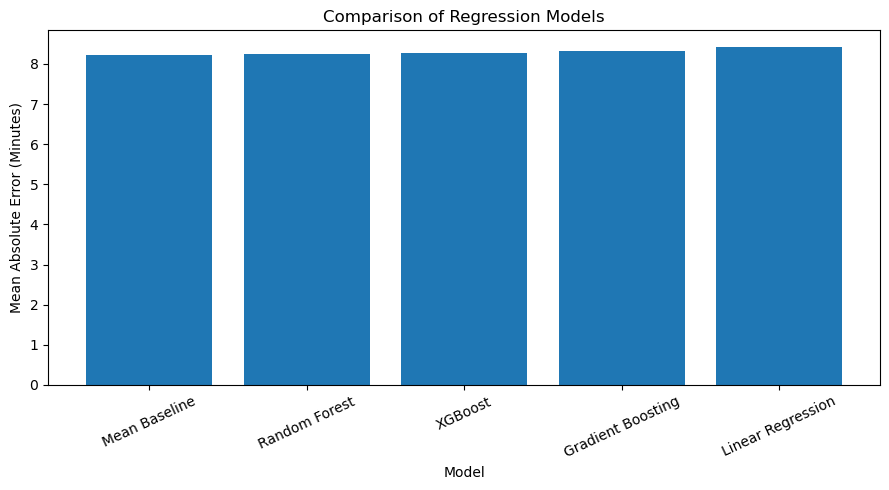

In [103]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["MAE"])
plt.title("Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (Minutes)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [104]:
results.to_csv("model_comparison_results.csv", index=False)

In [105]:
print("FINAL MODEL EVALUATION")
print("----------------------")
print("Best model:", results.iloc[0]["Model"])
print("Best MAE:", round(results.iloc[0]["MAE"], 3), "minutes")
print("Test records:", len(y_test))
print("Training records:", len(y_train))

FINAL MODEL EVALUATION
----------------------
Best model: Mean Baseline
Best MAE: 8.212 minutes
Test records: 400
Training records: 1600


In [106]:
conclusion = """
PROJECT CONCLUSION

The project focused on predicting public transport arrival delays
using weather, traffic, event and transport-related features.

A dataset containing 2,000 records and 24 original columns was
used. Data cleaning, exploratory data analysis and feature
engineering were performed.

Four regression models were evaluated:
Linear Regression, Random Forest, XGBoost and Gradient Boosting.

The Mean Baseline achieved the lowest MAE of 8.212 minutes.
None of the trained machine learning models outperformed it.

The results indicate weak predictive relationships between the
available features and arrival delay.

Future improvements could include larger real-world datasets,
historical delay information, route distance and real-time traffic.

The project demonstrates the complete machine learning workflow
and highlights the importance of data quality and feature relevance.
"""

print(conclusion)


PROJECT CONCLUSION

The project focused on predicting public transport arrival delays
using weather, traffic, event and transport-related features.

A dataset containing 2,000 records and 24 original columns was
used. Data cleaning, exploratory data analysis and feature
engineering were performed.

Four regression models were evaluated:
Linear Regression, Random Forest, XGBoost and Gradient Boosting.

The Mean Baseline achieved the lowest MAE of 8.212 minutes.
None of the trained machine learning models outperformed it.

The results indicate weak predictive relationships between the
available features and arrival delay.

Future improvements could include larger real-world datasets,
historical delay information, route distance and real-time traffic.

The project demonstrates the complete machine learning workflow
and highlights the importance of data quality and feature relevance.



In [107]:
with open("project_conclusion.txt", "w") as file:
    file.write(conclusion)

print("Conclusion saved!")

Conclusion saved!


In [108]:
import os

for file in os.listdir():
    print(file)

.ipynb_checkpoints
Backend
Frontend
model_comparison.png
model_comparison_results.csv
project_conclusion.txt
public_transport_delays.csv
public_transport_delays_cleaned.csv
Public_Transport_Delay_Prediction.ipynb
README.md
transport_delay_model.joblib
Untitled.ipynb


In [109]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

# Create a random train-test split for comparison
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_random, y_train_random)
baseline_predictions = baseline.predict(X_test_random)

# Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train_random, y_train_random)
rf_predictions = rf_model.predict(X_test_random)

print("BASELINE MAE:", mean_absolute_error(y_test_random, baseline_predictions))
print("RANDOM FOREST MAE:", mean_absolute_error(y_test_random, rf_predictions))
print("RANDOM FOREST R2:", r2_score(y_test_random, rf_predictions))

BASELINE MAE: 7.703031249999999
RANDOM FOREST MAE: 7.834376385880714
RANDOM FOREST R2: -0.03420056267412419


In [110]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd

X_check = X.copy()

for col in X_check.select_dtypes(include="object").columns:
    X_check[col] = OrdinalEncoder().fit_transform(
        X_check[[col]].astype(str)
    )

mi = mutual_info_regression(
    X_check.fillna(0),
    y,
    random_state=42
)

mi_results = pd.Series(mi, index=X_check.columns).sort_values(
    ascending=False
)

display(mi_results.to_frame("Information Score"))

,Information Score
event_attendance_est,0.027924
origin_station,0.013707
departure_day,0.010637
humidity_percent,0.010564
holiday,0.000362
peak_hour,0.000037
is_weekend,0.000000
departure_month,0.000000
departure_hour,0.000000
season,0.000000


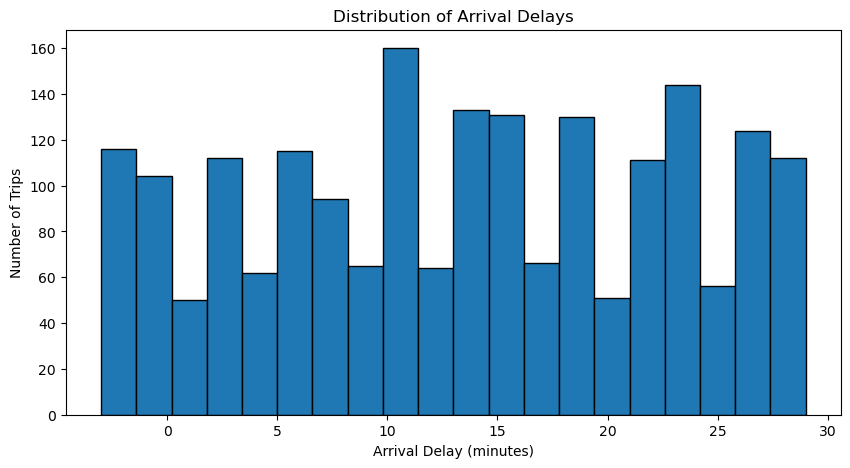

Unique delay values: 33
Mean delay: 13.318
Standard deviation: 9.289726880417733
Minimum delay: -3
Maximum delay: 29


In [111]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(y, bins=20, edgecolor="black")

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Trips")

plt.show()

print("Unique delay values:", y.nunique())
print("Mean delay:", y.mean())
print("Standard deviation:", y.std())
print("Minimum delay:", y.min())
print("Maximum delay:", y.max())

In [112]:
print("Duplicate rows:", df.duplicated().sum())

print("\nUnique values in each feature:")
display(df.nunique().sort_values().to_frame("Unique Values"))

print("\nCorrelation with arrival delay:")
display(
    df.select_dtypes(include="number")
      .corr()["actual_arrival_delay_min"]
      .sort_values(ascending=False)
)

Duplicate rows: 0

Unique values in each feature:


,Unique Values
departure_month,1
peak_hour,2
is_weekend,2
delayed,2
holiday,2
rush_hour_category,3
transport_type,4
season,4
event_type,5
event_attendance_est,5



Correlation with arrival delay:


actual_arrival_delay_min      1.000000
delayed                       0.763662
event_attendance_est          0.037266
scheduled_duration_min        0.035779
holiday                       0.033584
peak_hour                     0.002784
departure_day                 0.001659
precipitation_mm              0.001106
is_weekend                   -0.002647
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
departure_hour               -0.017650
humidity_percent             -0.027705
temperature_C                -0.039944
departure_month                    NaN
Name: actual_arrival_delay_min, dtype: float64

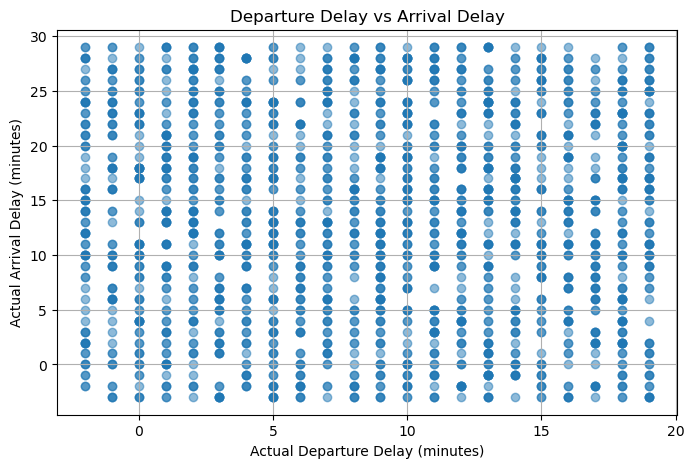

Correlation: -0.007161238616057809


In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["actual_departure_delay_min"],
    df["actual_arrival_delay_min"],
    alpha=0.5
)

plt.xlabel("Actual Departure Delay (minutes)")
plt.ylabel("Actual Arrival Delay (minutes)")
plt.title("Departure Delay vs Arrival Delay")
plt.grid(True)
plt.show()

print(
    "Correlation:",
    df["actual_departure_delay_min"].corr(
        df["actual_arrival_delay_min"]
    )
)

In [114]:

# STEP 1: DATASET QUALITY CHECK

import pandas as pd
import numpy as np

# 1. Dataset overview
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# 3. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Unique values in each column
print("\nUnique Values:")
print(df.nunique().sort_values())

# 5. Target variable analysis
target = "actual_arrival_delay_min"

print("\nTarget Statistics:")
print(df[target].describe())

# 6. Departure delay analysis
print("\nDeparture Delay Statistics:")
print(df["actual_departure_delay_min"].describe())

# 7. Correlation with target (numeric features only)
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()[target].drop(target)

print("\nFeature Correlation with Arrival Delay:")
display(
    correlation.abs()
    .sort_values(ascending=False)
    .to_frame("Absolute Correlation")
)

# 8. Check target leakage
if "delayed" in df.columns:
    print("\nWARNING: 'delayed' may be derived from the target.")
    print("Do not use it as a model input until its definition is verified.")


Dataset Shape: (2000, 30)

First 5 Rows:


,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,peak_hour,weekday,season,delayed,departure_hour,departure_day,departure_month,is_weekend,rush_hour_category,scheduled_duration_min
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,2023-01-01 05:02:00,2023-01-01 05:55:00,12,...,1,6,Winter,0,5,1,1,1,Non-Rush,53.0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,2023-01-01 05:16:00,2023-01-01 05:55:00,15,...,0,6,Autumn,1,5,1,1,1,Non-Rush,39.0
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,2023-01-01 05:33:00,2023-01-01 06:17:00,0,...,0,6,Autumn,0,5,1,1,1,Non-Rush,44.0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,2023-01-01 05:49:00,2023-01-01 06:08:00,15,...,0,6,Winter,1,5,1,1,1,Non-Rush,19.0
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,2023-01-01 06:00:00,2023-01-01 06:35:00,-1,...,0,6,Spring,1,6,1,1,1,Non-Rush,35.0



Missing Values:
event_type                    1173
trip_id                          0
date                             0
rush_hour_category               0
is_weekend                       0
departure_month                  0
departure_day                    0
departure_hour                   0
delayed                          0
season                           0
weekday                          0
peak_hour                        0
holiday                          0
traffic_congestion_index         0
event_attendance_est             0
precipitation_mm                 0
wind_speed_kmh                   0
humidity_percent                 0
temperature_C                    0
weather_condition                0
actual_arrival_delay_min         0
actual_departure_delay_min       0
scheduled_arrival                0
scheduled_departure              0
destination_station              0
origin_station                   0
route_id                         0
transport_type                   0
tim

,Absolute Correlation
delayed,0.763662
temperature_C,0.039944
event_attendance_est,0.037266
scheduled_duration_min,0.035779
holiday,0.033584
humidity_percent,0.027705
departure_hour,0.017650
traffic_congestion_index,0.011006
weekday,0.007785
wind_speed_kmh,0.007649



Do not use it as a model input until its definition is verified.


In [115]:

# STEP 2: INVESTIGATE POSSIBLE TARGET LEAKAGE

target = "actual_arrival_delay_min"

# Compare target statistics for delayed = 0 and delayed = 1
print("Arrival delay statistics by delayed column:")

display(
    df.groupby("delayed")[target].agg(
        ["count", "mean", "min", "max", "std"]
    )
)

# Check the relationship between delayed and arrival delay
print("\nAverage arrival delay for each delayed category:")

display(
    df.groupby("delayed")[target].mean()
)

# Check whether delayed is calculated using a threshold
print("\nTarget values for each delayed category:")

display(
    pd.crosstab(
        df[target],
        df["delayed"],
        margins=True
    )
)

# Check possible threshold rules
print("\nCheck common threshold rules:")

for threshold in [0, 1, 5, 10, 15]:
    matches = (
        (df[target] > threshold) == (df["delayed"] == 1)
    ).mean()

    print(f"Threshold > {threshold}: {matches * 100:.2f}% match")


Arrival delay statistics by delayed column:


,count,mean,min,max,std
delayed,,,,,
0,501,1.049900,-3,5,2.617538
1,1499,17.418279,6,29,6.761271



Average arrival delay for each delayed category:


delayed
0     1.049900
1    17.418279
Name: actual_arrival_delay_min, dtype: float64


Target values for each delayed category:


delayed,0,1,All
actual_arrival_delay_min,,,
-3,55,0,55
-2,61,0,61
-1,49,0,49
0,55,0,55
1,50,0,50
2,57,0,57
3,55,0,55
4,62,0,62
5,57,0,57



Check common threshold rules:
Threshold > 0: 85.95% match
Threshold > 1: 88.45% match
Threshold > 5: 100.00% match
Threshold > 10: 85.35% match
Threshold > 15: 68.20% match


In [116]:

# STEP 3: CHECK EVENT FEATURES

print("Event type distribution:")
display(df["event_type"].value_counts(dropna=False))

print("\nEvent attendance unique values:")
print(df["event_attendance_est"].value_counts(dropna=False))

print("\nArrival delay by event type:")
display(
    df.groupby("event_type", dropna=False)[
        "actual_arrival_delay_min"
    ].agg(["count", "mean", "median"])
)


Event type distribution:


event_type
NaN         1173
Festival     221
Sports       212
Concert      203
Parade       105
Protest       86
Name: count, dtype: int64


Event attendance unique values:
event_attendance_est
0        1216
50000     210
2000      210
10000     183
500       181
Name: count, dtype: int64

Arrival delay by event type:


,count,mean,median
event_type,,,
Concert,203,12.832512,13.0
Festival,221,12.769231,13.0
Parade,105,13.619048,14.0
Protest,86,13.895349,13.0
Sports,212,12.820755,13.0
NaN,1173,13.526002,14.0


In [117]:

# STEP 5: EVENT DATA CONSISTENCY CHECK

print("Event Type vs Event Attendance:")

display(
    pd.crosstab(
        df["event_type"].fillna("No Event"),
        df["event_attendance_est"],
        margins=True
    )
)

print("\nAverage arrival delay by attendance:")

display(
    df.groupby("event_attendance_est")[
        "actual_arrival_delay_min"
    ].agg(["count", "mean", "median", "std"])
)

print("\nMissing event type vs zero attendance:")

print(
    pd.crosstab(
        df["event_type"].isna(),
        df["event_attendance_est"].eq(0),
        rownames=["Event Type Missing"],
        colnames=["Attendance is Zero"]
    )
)


Event Type vs Event Attendance:


event_attendance_est,0,500,2000,10000,50000,All
event_type,,,,,,
Concert,121,16,22,24,20,203
Festival,134,18,12,23,34,221
No Event,713,106,133,100,121,1173
Parade,60,15,15,9,6,105
Protest,52,11,9,6,8,86
Sports,136,15,19,21,21,212
All,1216,181,210,183,210,2000



Average arrival delay by attendance:


,count,mean,median,std
event_attendance_est,,,,
0,1216,12.990132,13.0,9.190614
500,181,12.790055,12.0,9.225575
2000,210,14.404762,15.0,9.165829
10000,183,13.754098,14.0,9.475223
50000,210,14.204762,14.0,9.791168



Missing event type vs zero attendance:
Attendance is Zero  False  True 
Event Type Missing              
False                 324    503
True                  460    713


Feature shape: (2000, 21)
Target shape: (2000,)

Features:
['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'departure_hour', 'departure_day', 'is_weekend', 'rush_hour_category', 'scheduled_duration_min']

Training records: 1600
Testing records: 400

MODEL PERFORMANCE COMPARISON:


,Model,MAE,RMSE,R2 Score
0,Baseline,7.7030,9.1901,-0.0017
2,Random Forest,7.8033,9.3020,-0.0262
3,Gradient Boosting,7.8483,9.3215,-0.0306
1,Linear Regression,8.0177,9.6281,-0.0995


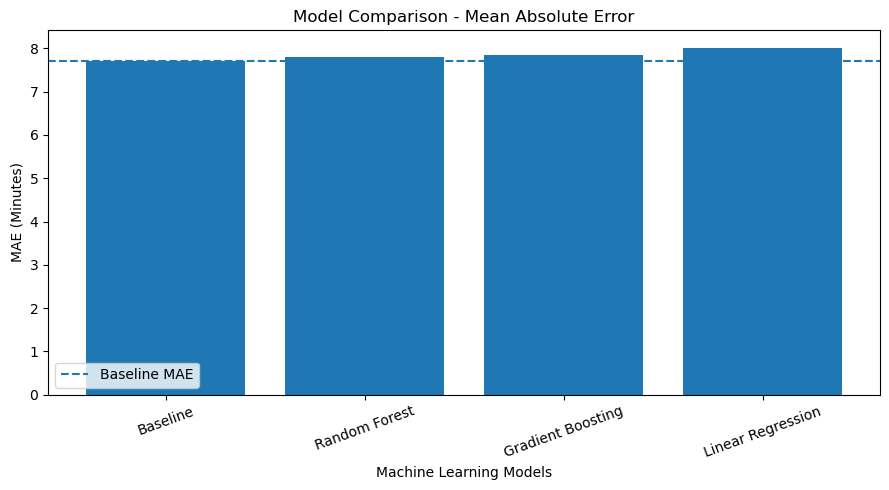


Best model based on MAE: Baseline
Best MAE: 7.703


In [118]:

# PUBLIC TRANSPORT DELAY PREDICTION
# First leakage-free regression experiment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -----------------------------------
# 1. Define target and clean features
# -----------------------------------

target = "actual_arrival_delay_min"

X = df.drop(columns=[
    target,
    "delayed",
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "departure_month"
], errors="ignore")

y = df[target]

# Convert missing event types into an explicit category
if "event_type" in X.columns:
    X["event_type"] = X["event_type"].fillna("No Event")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

# -----------------------------------
# 2. Split training and testing data
# -----------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# -----------------------------------
# 3. Identify numeric and categorical columns
# -----------------------------------

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# -----------------------------------
# 4. Preprocessing
# -----------------------------------

def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

# -----------------------------------
# 5. Define regression models
# -----------------------------------

models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# -----------------------------------
# 6. Train and evaluate models
# -----------------------------------

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", create_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

# -----------------------------------
# 7. Display comparison
# -----------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE")

print("\nMODEL PERFORMANCE COMPARISON:")
display(results_df.round(4))

# -----------------------------------
# 8. Plot MAE comparison
# -----------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.axhline(
    y=results_df.loc[
        results_df["Model"] == "Baseline", "MAE"
    ].iloc[0],
    linestyle="--",
    label="Baseline MAE"
)

plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Machine Learning Models")
plt.ylabel("MAE (Minutes)")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------------
# 9. Best model
# -----------------------------------

best_model_name = results_df.iloc[0]["Model"]

print("\nBest model based on MAE:", best_model_name)
print("Best MAE:", round(results_df.iloc[0]["MAE"], 4))


PERMUTATION FEATURE IMPORTANCE:


,Feature,Importance,Std
6,humidity_percent,0.01460,0.01589
4,weather_condition,0.00709,0.00749
11,traffic_congestion_index,0.00675,0.00753
20,scheduled_duration_min,0.00433,0.01157
10,event_attendance_est,0.00237,0.01620
3,destination_station,0.00231,0.01299
13,peak_hour,0.00157,0.00256
1,route_id,0.00117,0.00836
15,season,-0.00090,0.00928
18,is_weekend,-0.00145,0.00061


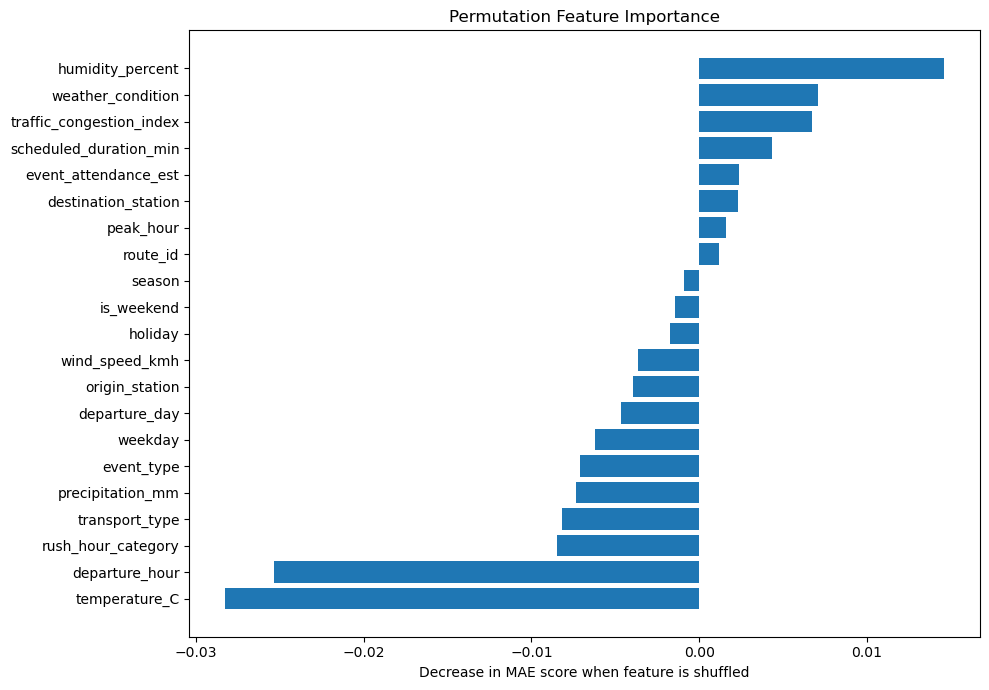

In [119]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest pipeline
rf_model = trained_models["Random Forest"]

# Calculate permutation importance on test data
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=15,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("PERMUTATION FEATURE IMPORTANCE:")
display(importance_df.round(5))

# Plot results
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Decrease in MAE score when feature is shuffled")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


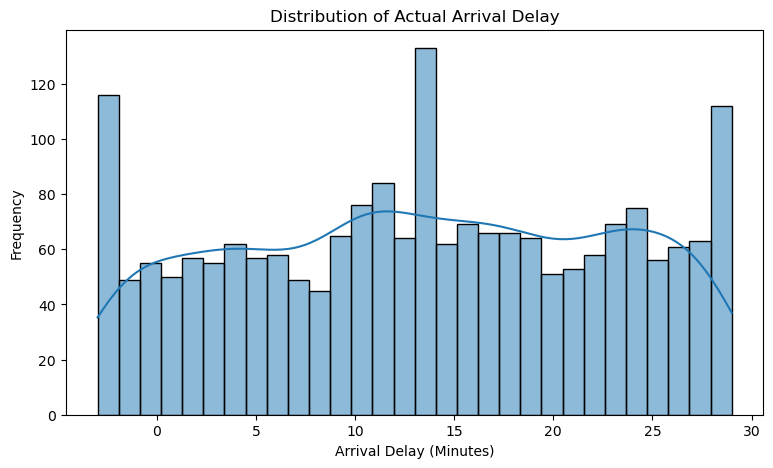

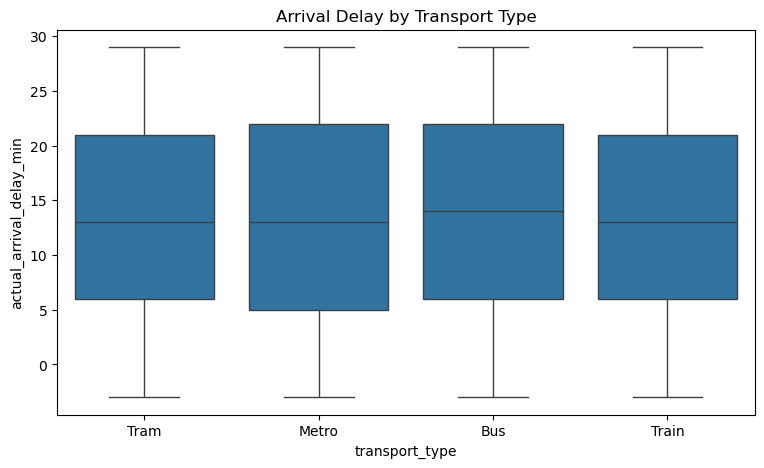

Arrival delay by route:


,mean,count
route_id,,
Route_10,11.813953,86
Route_13,11.928571,112
Route_4,12.682692,104
Route_9,12.831683,101
Route_3,13.070175,114
Route_16,13.162500,80
Route_2,13.218182,110
Route_8,13.311927,109
Route_11,13.340909,88



Arrival delay by humidity_percent:


,count,mean,median,std
feature_bin,,,,
"(29.999, 43.0]",414,14.198068,14.5,9.235388
"(43.0, 58.0]",412,13.186893,13.0,9.389725
"(58.0, 72.0]",377,12.737401,13.0,9.119625
"(72.0, 86.0]",419,12.921241,13.0,9.374250
"(86.0, 99.0]",378,13.515873,13.5,9.286253


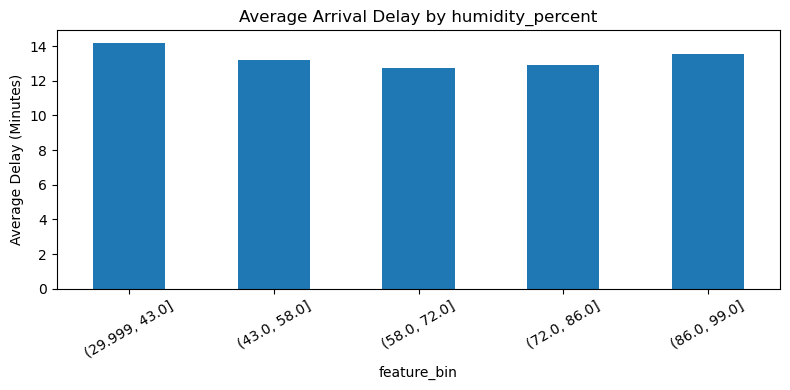


Arrival delay by traffic_congestion_index:


,count,mean,median,std
feature_bin,,,,
"(-0.001, 20.0]",402,13.236318,13.0,9.013228
"(20.0, 40.0]",409,13.173594,13.0,9.241938
"(40.0, 62.0]",405,14.009877,14.0,9.349903
"(62.0, 81.0]",401,13.074813,13.0,9.434479
"(81.0, 99.0]",383,13.080940,13.0,9.422388


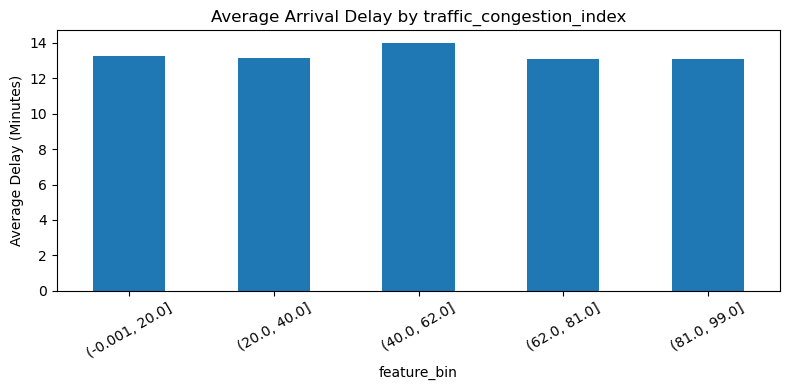


Arrival delay by temperature_C:


,count,mean,median,std
feature_bin,,,,
"(-5.001, 3.3]",402,13.741294,14.0,9.232802
"(3.3, 10.9]",399,13.303258,14.0,9.233747
"(10.9, 18.9]",402,13.482587,14.0,9.339319
"(18.9, 27.2]",398,13.537688,13.0,9.383642
"(27.2, 35.0]",399,12.521303,12.0,9.257018


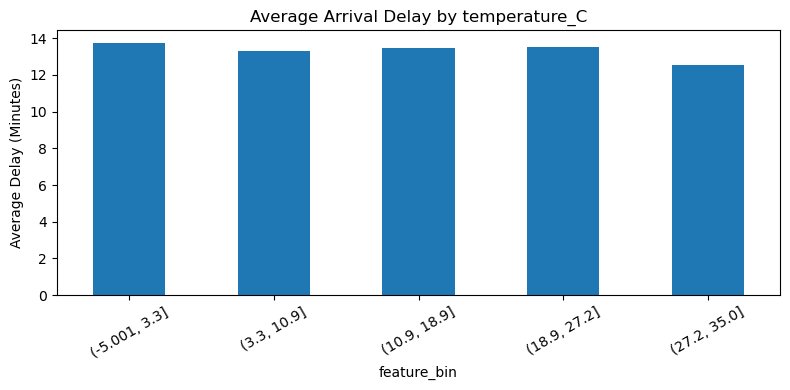


Arrival delay by scheduled_duration_min:


,count,mean,median,std
feature_bin,,,,
"(-1422.001, 25.0]",441,13.691610,14.0,9.136597
"(25.0, 32.6]",359,13.518106,13.0,9.570035
"(32.6, 40.0]",407,12.326781,12.0,9.322828
"(40.0, 48.0]",402,14.333333,15.0,9.151991
"(48.0, 59.0]",391,12.700767,13.0,9.209804


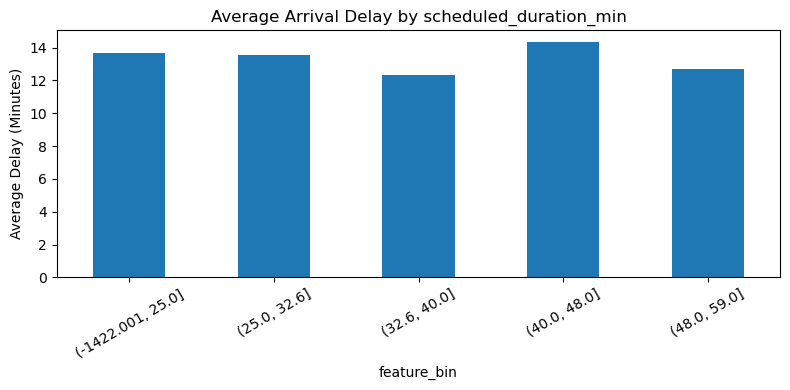


Arrival delay by event_attendance_est:


,count,mean,median,std
feature_bin,,,,
"(-0.001, 2000.0]",1607,13.152458,13.0,9.19864
"(2000.0, 50000.0]",393,13.994911,14.0,9.63571


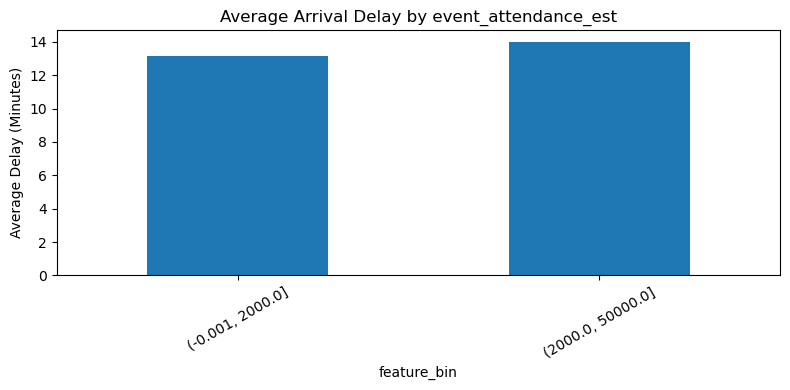

In [120]:

# STEP 6: FEATURE RELATIONSHIP ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    df["actual_arrival_delay_min"],
    bins=30,
    kde=True
)
plt.title("Distribution of Actual Arrival Delay")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")
plt.show()


# 2. Average delay by transport type
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="transport_type",
    y="actual_arrival_delay_min"
)
plt.title("Arrival Delay by Transport Type")
plt.show()


# 3. Average delay by route
route_delay = df.groupby("route_id")[
    "actual_arrival_delay_min"
].agg(["mean", "count"]).sort_values("mean")

print("Arrival delay by route:")
display(route_delay)


# 4. Numeric feature relationships using bins
numeric_features = [
    "humidity_percent",
    "traffic_congestion_index",
    "temperature_C",
    "scheduled_duration_min",
    "event_attendance_est"
]

for feature in numeric_features:

    df["feature_bin"] = pd.qcut(
        df[feature],
        q=5,
        duplicates="drop"
    )

    grouped = df.groupby(
        "feature_bin",
        observed=False
    )["actual_arrival_delay_min"].agg(
        ["count", "mean", "median", "std"]
    )

    print(f"\nArrival delay by {feature}:")
    display(grouped)

    plt.figure(figsize=(8, 4))
    grouped["mean"].plot(kind="bar")
    plt.title(f"Average Arrival Delay by {feature}")
    plt.ylabel("Average Delay (Minutes)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

df.drop(columns=["feature_bin"], inplace=True)


In [121]:

# STEP 7: INVESTIGATE SCHEDULED DURATION

print("Scheduled duration statistics:")
print(df["scheduled_duration_min"].describe())

# Check negative durations
negative_duration = df[
    df["scheduled_duration_min"] < 0
]

print("\nNegative duration records:")
display(negative_duration[[
    "date",
    "scheduled_departure",
    "scheduled_arrival",
    "scheduled_duration_min",
    "actual_arrival_delay_min"
]])

# Check zero durations
print("\nZero duration records:")
print(
    (df["scheduled_duration_min"] == 0).sum()
)

# Recalculate duration from timestamps
df["scheduled_departure"] = pd.to_datetime(
    df["scheduled_departure"]
)

df["scheduled_arrival"] = pd.to_datetime(
    df["scheduled_arrival"]
)

df["calculated_duration"] = (
    df["scheduled_arrival"] -
    df["scheduled_departure"]
).dt.total_seconds() / 60

print("\nCalculated duration statistics:")
print(df["calculated_duration"].describe())

print("\nCompare original and calculated duration:")
display(
    df[[
        "scheduled_duration_min",
        "calculated_duration"
    ]].head(20)
)

print(
    "\nMismatched duration records:",
    (
        df["scheduled_duration_min"] !=
        df["calculated_duration"]
    ).sum()
)


Scheduled duration statistics:
count    2000.000000
mean        4.603500
std       213.411993
min     -1422.000000
25%        27.000000
50%        36.000000
75%        46.000000
max        59.000000
Name: scheduled_duration_min, dtype: float64

Negative duration records:


,date,scheduled_departure,scheduled_arrival,scheduled_duration_min,actual_arrival_delay_min
75,2023-01-01,2023-01-01 23:47:00,2023-01-01 00:38:00,-1389.0,-2
170,2023-01-02,2023-01-02 23:30:00,2023-01-02 00:03:00,-1407.0,-2
171,2023-01-02,2023-01-02 23:49:00,2023-01-02 00:38:00,-1391.0,11
266,2023-01-03,2023-01-03 23:33:00,2023-01-03 00:27:00,-1386.0,15
267,2023-01-03,2023-01-03 23:46:00,2023-01-03 00:15:00,-1411.0,2
363,2023-01-04,2023-01-04 23:46:00,2023-01-04 00:09:00,-1417.0,8
457,2023-01-05,2023-01-05 23:17:00,2023-01-05 00:00:00,-1397.0,9
458,2023-01-05,2023-01-05 23:31:00,2023-01-05 00:19:00,-1392.0,3
459,2023-01-05,2023-01-05 23:46:00,2023-01-05 00:37:00,-1389.0,12
554,2023-01-06,2023-01-06 23:30:00,2023-01-06 00:15:00,-1395.0,26



Zero duration records:
0

Calculated duration statistics:
count    2000.000000
mean        4.603500
std       213.411993
min     -1422.000000
25%        27.000000
50%        36.000000
75%        46.000000
max        59.000000
Name: calculated_duration, dtype: float64

Compare original and calculated duration:


,scheduled_duration_min,calculated_duration
0,53.0,53.0
1,39.0,39.0
2,44.0,44.0
3,19.0,19.0
4,35.0,35.0
5,41.0,41.0
6,27.0,27.0
7,33.0,33.0
8,58.0,58.0
9,55.0,55.0



Mismatched duration records: 0


Target value frequency:


,Frequency
actual_arrival_delay_min,
-3,55
-2,61
-1,49
0,55
1,50
2,57
3,55
4,62
5,57


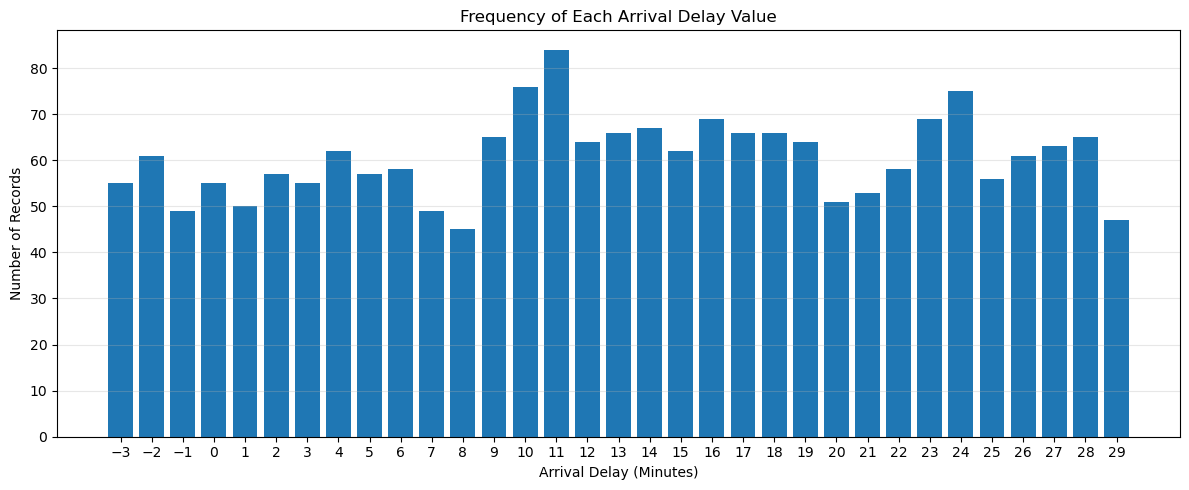

In [122]:

# STEP 8: TARGET VALUE FREQUENCY

target_counts = df[
    "actual_arrival_delay_min"
].value_counts().sort_index()

print("Target value frequency:")
display(target_counts.to_frame("Frequency"))

plt.figure(figsize=(12, 5))

plt.bar(
    target_counts.index,
    target_counts.values
)

plt.title("Frequency of Each Arrival Delay Value")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Records")
plt.xticks(range(-3, 30))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [123]:

# STEP 9: FIX MIDNIGHT CROSSING ERRORS

# Convert timestamps
df["scheduled_departure"] = pd.to_datetime(
    df["scheduled_departure"]
)

df["scheduled_arrival"] = pd.to_datetime(
    df["scheduled_arrival"]
)

# Correct arrival timestamps where arrival is earlier
# than departure by moving arrival to the next day
corrected_arrival = df["scheduled_arrival"].copy()

midnight_crossing = (
    corrected_arrival < df["scheduled_departure"]
)

corrected_arrival.loc[midnight_crossing] += pd.Timedelta(days=1)

# Recalculate journey duration
df["scheduled_duration_min"] = (
    corrected_arrival - df["scheduled_departure"]
).dt.total_seconds() / 60

# Display results
print("Midnight crossing records:", midnight_crossing.sum())

print("\nCorrected duration statistics:")
print(df["scheduled_duration_min"].describe())

print("\nNegative durations remaining:")
print((df["scheduled_duration_min"] < 0).sum())

print("\nCorrected sample:")
display(
    df.loc[midnight_crossing, [
        "scheduled_departure",
        "scheduled_arrival",
        "scheduled_duration_min"
    ]].head(10)
)


Midnight crossing records: 45

Corrected duration statistics:
count    2000.000000
mean       37.003500
std        11.341243
min        16.000000
25%        27.000000
50%        37.000000
75%        47.000000
max        59.000000
Name: scheduled_duration_min, dtype: float64

Negative durations remaining:
0

Corrected sample:


,scheduled_departure,scheduled_arrival,scheduled_duration_min
75,2023-01-01 23:47:00,2023-01-01 00:38:00,51.0
170,2023-01-02 23:30:00,2023-01-02 00:03:00,33.0
171,2023-01-02 23:49:00,2023-01-02 00:38:00,49.0
266,2023-01-03 23:33:00,2023-01-03 00:27:00,54.0
267,2023-01-03 23:46:00,2023-01-03 00:15:00,29.0
363,2023-01-04 23:46:00,2023-01-04 00:09:00,23.0
457,2023-01-05 23:17:00,2023-01-05 00:00:00,43.0
458,2023-01-05 23:31:00,2023-01-05 00:19:00,48.0
459,2023-01-05 23:46:00,2023-01-05 00:37:00,51.0
554,2023-01-06 23:30:00,2023-01-06 00:15:00,45.0


UPDATED MODEL PERFORMANCE:


,Model,Train MAE,Test MAE,RMSE,R2 Score
0,Baseline,8.0157,7.7030,9.1901,-0.0017
2,Random Forest,6.8398,7.8079,9.3062,-0.0272
3,Gradient Boosting,7.5023,7.8448,9.3272,-0.0318
1,Linear Regression,7.5532,8.0322,9.6349,-0.1010


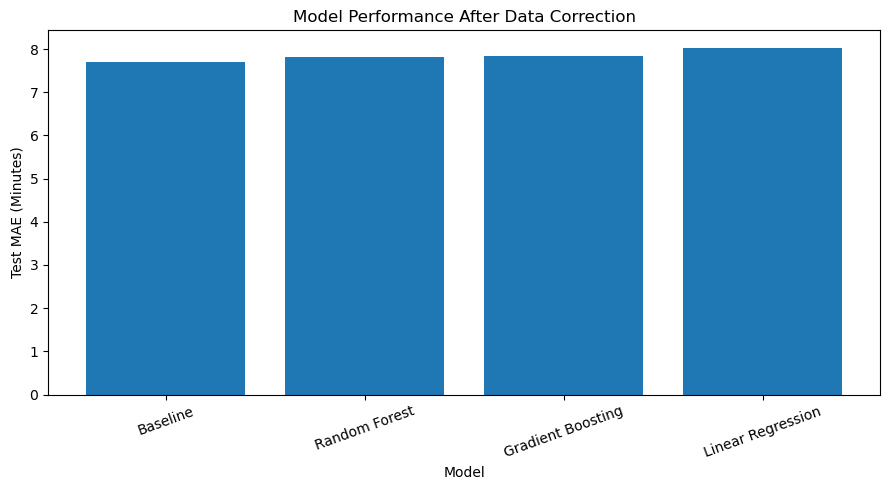

Best model: Baseline
Best test MAE: 7.703


In [124]:

# STEP 10: RETRAIN MODELS WITH CORRECTED DATA

# 1. Recreate features and target
target = "actual_arrival_delay_min"

X = df.drop(columns=[
    target,
    "delayed",
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "departure_month"
], errors="ignore")

y = df[target]

# Handle missing event types
if "event_type" in X.columns:
    X["event_type"] = X["event_type"].fillna("No Event")

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# 3. Identify feature types
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# 4. Preprocessing
def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

# 5. Models
models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# 6. Training and evaluation
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", create_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    train_mae = mean_absolute_error(
        y_train, train_predictions
    )

    test_mae = mean_absolute_error(
        y_test, test_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    r2 = r2_score(y_test, test_predictions)

    results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

# 7. Comparison table
results_df = pd.DataFrame(results).sort_values(
    "Test MAE"
)

print("UPDATED MODEL PERFORMANCE:")
display(results_df.round(4))

# 8. MAE comparison graph
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Test MAE"]
)

plt.title("Model Performance After Data Correction")
plt.xlabel("Model")
plt.ylabel("Test MAE (Minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Best model:", results_df.iloc[0]["Model"])
print("Best test MAE:", round(
    results_df.iloc[0]["Test MAE"], 4
))


actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64


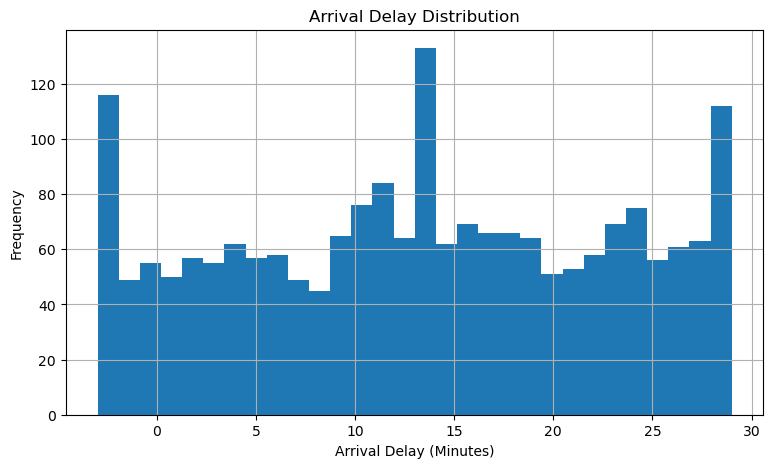

In [125]:
print(df["actual_arrival_delay_min"].value_counts().sort_index())

df["actual_arrival_delay_min"].hist(bins=30, figsize=(9, 5))
plt.title("Arrival Delay Distribution")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")
plt.show()

In [126]:

# STEP 11: TARGET RANDOMNESS AND CHRONOLOGICAL VALIDATION

from scipy.stats import chisquare
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------
# TEST 1: Uniform distribution test
# --------------------------------

target_counts = (
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
)

expected_frequency = len(df) / len(target_counts)

chi_stat, p_value = chisquare(
    target_counts.values,
    f_exp=[expected_frequency] * len(target_counts)
)

print("TARGET DISTRIBUTION TEST")
print("Unique target values:", len(target_counts))
print("Expected frequency per value:", expected_frequency)
print("Chi-square statistic:", chi_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Target frequencies differ significantly from uniform.")
else:
    print("No significant difference from a uniform distribution was detected.")

# --------------------------------
# TEST 2: Chronological validation
# --------------------------------

# Sort records by date and scheduled departure
df_sorted = df.sort_values(
    ["scheduled_departure"]
).reset_index(drop=True)

# Keep the same clean feature exclusions
X_time = df_sorted.drop(columns=[
    "actual_arrival_delay_min",
    "delayed",
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "departure_month"
], errors="ignore")

y_time = df_sorted["actual_arrival_delay_min"]

# First 80% for training, last 20% for testing
split_index = int(len(df_sorted) * 0.8)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

print("\nCHRONOLOGICAL SPLIT")
print("Training records:", len(X_train_time))
print("Testing records:", len(X_test_time))
print("Training date range:",
      df_sorted["date"].iloc[0],
      "to",
      df_sorted["date"].iloc[split_index - 1])
print("Testing date range:",
      df_sorted["date"].iloc[split_index],
      "to",
      df_sorted["date"].iloc[-1])

# Identify columns
num_time = X_train_time.select_dtypes(
    include=np.number
).columns.tolist()

cat_time = X_train_time.select_dtypes(
    exclude=np.number
).columns.tolist()

# Build preprocessing pipeline
preprocessor_time = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_time),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_time)
])

# Train Random Forest
temporal_rf = Pipeline([
    ("preprocessing", preprocessor_time),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

temporal_rf.fit(X_train_time, y_train_time)

predictions = temporal_rf.predict(X_test_time)

# Baseline using training mean only
baseline_predictions = np.full(
    len(y_test_time),
    y_train_time.mean()
)

print("\nCHRONOLOGICAL MODEL RESULTS")

print("Baseline MAE:",
      mean_absolute_error(y_test_time, baseline_predictions))

print("Random Forest MAE:",
      mean_absolute_error(y_test_time, predictions))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test_time, predictions)))

print("Random Forest R2:",
      r2_score(y_test_time, predictions))


TARGET DISTRIBUTION TEST
Unique target values: 33
Expected frequency per value: 60.60606060606061
Chi-square statistic: 40.38999999999999
P-value: 0.1466854566248402
No significant difference from a uniform distribution was detected.

CHRONOLOGICAL SPLIT
Training records: 1600
Testing records: 400
Training date range: 2023-01-01 00:00:00 to 2023-01-17 00:00:00
Testing date range: 2023-01-17 00:00:00 to 2023-01-22 00:00:00

CHRONOLOGICAL MODEL RESULTS
Baseline MAE: 8.154625
Random Forest MAE: 8.176568388569951
Random Forest RMSE: 9.491140996153284
Random Forest R2: -0.010978959608545669


In [127]:

# STEP 12: FINAL MODEL TRAINING AND EXPORT

import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# 1. Prepare final features
target = "actual_arrival_delay_min"

X_final = df.drop(columns=[
    target,
    "delayed",
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "departure_month"
], errors="ignore")

y_final = df[target]

# Handle missing event information
if "event_type" in X_final.columns:
    X_final["event_type"] = X_final["event_type"].fillna("No Event")

# 2. Identify feature types
numeric_features = X_final.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_final.select_dtypes(
    exclude=np.number
).columns.tolist()

# 3. Build preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# 4. Final Random Forest model
final_model = Pipeline([
    ("preprocessing", preprocessor),

    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. Train on complete dataset
final_model.fit(X_final, y_final)

# 6. Save complete pipeline
model_bundle = {
    "model": final_model,
    "features": X_final.columns.tolist(),
    "target": target,
    "model_name": "Random Forest Regressor"
}

joblib.dump(
    model_bundle,
    "transport_delay_model.joblib"
)

print("Final model trained successfully!")
print("Model saved as transport_delay_model.joblib")
print("Number of training records:", len(X_final))
print("Number of input features:", len(X_final.columns))

# 7. Test loading the saved model
loaded_bundle = joblib.load(
    "transport_delay_model.joblib"
)

loaded_model = loaded_bundle["model"]

sample = X_final.iloc[[0]]
prediction = loaded_model.predict(sample)[0]

print("\nSample predicted arrival delay:",
      round(prediction, 2), "minutes")


Final model trained successfully!
Model saved as transport_delay_model.joblib
Number of training records: 2000
Number of input features: 22

Sample predicted arrival delay: 12.0 minutes


In [128]:
import os

print("Current directory:", os.getcwd())
print("Model exists:", os.path.exists("transport_delay_model.joblib"))

Current directory: E:\Data Science Course\Public_Transport_Delay_Prediction
Model exists: True


In [129]:
import os

model_path = os.path.abspath("transport_delay_model.joblib")

print("Your model location:", model_path)

Your model location: E:\Data Science Course\Public_Transport_Delay_Prediction\transport_delay_model.joblib


In [130]:
import joblib

model_bundle = joblib.load("transport_delay_model.joblib")

loaded_model = model_bundle["model"]

sample = X_final.iloc[[0]]

prediction = loaded_model.predict(sample)[0]

print("Predicted Arrival Delay:", round(prediction, 2), "minutes")

Predicted Arrival Delay: 12.0 minutes


In [131]:
import sys
print(sys.executable)

E:\ANACONDA\python.exe


In [132]:
import json
import os

# Take one real sample from the model's training features
sample_input = X_final.iloc[0].to_dict()

# Save it as JSON for API testing
output_path = r"E:\DAta Science Course\Public_Transport_Delay_Prediction\Backend\sample_input.json"

with open(output_path, "w") as file:
    json.dump(sample_input, file, default=str)

print("Sample input saved successfully!")
print(sample_input)

Sample input saved successfully!
{'transport_type': 'Tram', 'route_id': 'Route_15', 'origin_station': 'Station_31', 'destination_station': 'Station_6', 'weather_condition': 'Storm', 'temperature_C': 5.1, 'humidity_percent': 52, 'wind_speed_kmh': 46, 'precipitation_mm': 13.0, 'event_type': 'No Event', 'event_attendance_est': 500, 'traffic_congestion_index': 81, 'holiday': 0, 'peak_hour': 1, 'weekday': 6, 'season': 'Winter', 'departure_hour': 5, 'departure_day': 1, 'is_weekend': 1, 'rush_hour_category': 'Non-Rush', 'scheduled_duration_min': 53.0, 'calculated_duration': 53.0}


In [133]:
print("Data type:")
print(X_final["calculated_duration"].dtype)

print("\nStatistics:")
print(X_final["calculated_duration"].describe())

print("\nSample values:")
print(X_final["calculated_duration"].head(10))

Data type:
float64

Statistics:
count    2000.000000
mean        4.603500
std       213.411993
min     -1422.000000
25%        27.000000
50%        36.000000
75%        46.000000
max        59.000000
Name: calculated_duration, dtype: float64

Sample values:
0    53.0
1    39.0
2    44.0
3    19.0
4    35.0
5    41.0
6    27.0
7    33.0
8    58.0
9    55.0
Name: calculated_duration, dtype: float64


In [134]:
print(X_final[
    [
        "scheduled_duration_min",
        "calculated_duration"
    ]
].head(15))

    scheduled_duration_min  calculated_duration
0                     53.0                 53.0
1                     39.0                 39.0
2                     44.0                 44.0
3                     19.0                 19.0
4                     35.0                 35.0
5                     41.0                 41.0
6                     27.0                 27.0
7                     33.0                 33.0
8                     58.0                 58.0
9                     55.0                 55.0
10                    56.0                 56.0
11                    44.0                 44.0
12                    33.0                 33.0
13                    27.0                 27.0
14                    56.0                 56.0


In [135]:
print(
    X_final[
        ["scheduled_duration_min", "calculated_duration"]
    ].corr()
)

                        scheduled_duration_min  calculated_duration
scheduled_duration_min                1.000000             0.009141
calculated_duration                   0.009141             1.000000


In [137]:
df = pd.read_csv("public_transport_delays.csv")

In [138]:

# STEP 1: Dataset inspection

print("DATASET SHAPE:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nTARGET VARIABLE SUMMARY:")
print(df["actual_arrival_delay_min"].describe())

print("\nFIRST 5 ROWS:")
display(df.head())


DATASET SHAPE: (2000, 24)

COLUMN NAMES:
['trip_id', 'date', 'time', 'transport_type', 'route_id', 'origin_station', 'destination_station', 'scheduled_departure', 'scheduled_arrival', 'actual_departure_delay_min', 'actual_arrival_delay_min', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'delayed']

DATA TYPES:
trip_id                        object
date                           object
time                           object
transport_type                 object
route_id                       object
origin_station                 object
destination_station            object
scheduled_departure            object
scheduled_arrival              object
actual_departure_delay_min      int64
actual_arrival_delay_min        int64
weather_condition              object
temperature_C                 float64
humidity_percent                i

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1


In [139]:

# STEP 2: Investigating relationships in the dataset

import pandas as pd
import numpy as np

target = "actual_arrival_delay_min"

# 1. Target distribution
print("DELAY DISTRIBUTION")
print(df[target].value_counts(bins=5).sort_index())

# 2. Correlation with numerical features
print("\nNUMERICAL FEATURE CORRELATION")

numeric_df = df.select_dtypes(include=["number"])

correlation = numeric_df.corr()[target].drop(target)
print(correlation.sort_values(ascending=False))

# 3. Average delay by transport type
print("\nAVERAGE DELAY BY TRANSPORT TYPE")
print(
    df.groupby("transport_type")[target]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

# 4. Average delay by weather
print("\nAVERAGE DELAY BY WEATHER")
print(
    df.groupby("weather_condition")[target]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

# 5. Average delay by event type
print("\nAVERAGE DELAY BY EVENT TYPE")
print(
    df.assign(event_type_clean=df["event_type"].fillna("No Event"))
    .groupby("event_type_clean")[target]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

# 6. Delayed vs not delayed
print("\nDELAYED CLASS DISTRIBUTION")
print(df["delayed"].value_counts())
print("\nDELAYED CLASS PERCENTAGE")
print(df["delayed"].value_counts(normalize=True) * 100)

# 7. Duplicate records
print("\nDUPLICATE ROWS:", df.duplicated().sum())

# 8. Actual departure delay relationship
print("\nACTUAL DEPARTURE DELAY CORRELATION:")
print(df["actual_departure_delay_min"].corr(df[target]))

print("\nANALYSIS COMPLETED")


DELAY DISTRIBUTION
(-3.033, 3.4]    382
(3.4, 9.8]       336
(9.8, 16.2]      488
(16.2, 22.6]     358
(22.6, 29.0]     436
Name: count, dtype: int64

NUMERICAL FEATURE CORRELATION
delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
precipitation_mm              0.001106
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
humidity_percent             -0.027705
temperature_C                -0.039944
Name: actual_arrival_delay_min, dtype: float64

AVERAGE DELAY BY TRANSPORT TYPE
                     mean  median  count
transport_type                          
Train           13.547667    13.0    493
Bus             13.540952    14.0    525
Metro           13.213849    13.0    491
Tram            12.953157    13.0    491

AVERAGE DELAY BY WEATHER
                        mean  median  

In [140]:

# STEP 3: Deeper dataset investigation

import pandas as pd
import numpy as np

# Work on a copy. Original dataset remains unchanged.
analysis_df = df.copy()

# Convert date and scheduled times
analysis_df["date"] = pd.to_datetime(analysis_df["date"], errors="coerce")

analysis_df["scheduled_departure"] = pd.to_datetime(
    analysis_df["scheduled_departure"], format="%H:%M:%S", errors="coerce"
)

analysis_df["scheduled_arrival"] = pd.to_datetime(
    analysis_df["scheduled_arrival"], format="%H:%M:%S", errors="coerce"
)

# Extract departure hour
analysis_df["departure_hour"] = (
    analysis_df["scheduled_departure"].dt.hour
)

# Calculate scheduled journey duration, correcting midnight crossing
departure_minutes = (
    analysis_df["scheduled_departure"].dt.hour * 60
    + analysis_df["scheduled_departure"].dt.minute
)

arrival_minutes = (
    analysis_df["scheduled_arrival"].dt.hour * 60
    + analysis_df["scheduled_arrival"].dt.minute
)

analysis_df["scheduled_duration_min"] = (
    arrival_minutes - departure_minutes
) % 1440

# 1. Delay by departure hour
print("AVERAGE DELAY BY DEPARTURE HOUR")

print(
    analysis_df.groupby("departure_hour")["actual_arrival_delay_min"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 2. Delay by scheduled journey duration
print("\nAVERAGE DELAY BY SCHEDULED DURATION")

print(
    analysis_df.groupby(
        pd.cut(analysis_df["scheduled_duration_min"], bins=5)
    )["actual_arrival_delay_min"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 3. Routes with highest average delay
print("\nTOP 10 ROUTES BY AVERAGE DELAY")

print(
    analysis_df.groupby("route_id")["actual_arrival_delay_min"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
    .head(10)
    .round(2)
)

# 4. Delay by month
analysis_df["month"] = analysis_df["date"].dt.month

print("\nAVERAGE DELAY BY MONTH")

print(
    analysis_df.groupby("month")["actual_arrival_delay_min"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 5. Correlation with derived time and duration features
print("\nCORRELATION WITH DERIVED FEATURES")

print(
    analysis_df[
        [
            "actual_arrival_delay_min",
            "departure_hour",
            "scheduled_duration_min"
        ]
    ].corr()["actual_arrival_delay_min"]
)

# 6. Compare target variability
print("\nTARGET VARIABILITY")

print("Target standard deviation:", df["actual_arrival_delay_min"].std())
print("Target unique values:", df["actual_arrival_delay_min"].nunique())
print("Target value counts:")
print(df["actual_arrival_delay_min"].value_counts().sort_index())

print("\nSTEP 3 COMPLETED")


AVERAGE DELAY BY DEPARTURE HOUR
                 mean  median  count
departure_hour                      
0               12.05    11.5     84
1               14.50    15.0     80
2               14.66    15.5     80
3               14.52    14.0     80
4               11.20    11.0     80
5               12.95    12.0     84
6               11.87    10.5     84
7               13.88    14.0     84
8               14.39    15.5     84
9               13.46    13.0     84
10              13.64    14.0     84
11              12.05    12.0     84
12              14.25    17.0     84
13              13.76    15.0     84
14              15.58    18.0     84
15              13.23    14.0     84
16              14.73    16.0     84
17              13.11    11.5     84
18              12.73    13.0     84
19              13.32    14.5     84
20              12.65    13.5     84
21              11.82    11.0     84
22              13.20    14.0     84
23              12.14    11.0     84

AVERA

C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_13252\3219482002.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  analysis_df.groupby(


In [141]:

# STEP 4: Check target distribution and feature information

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd
import numpy as np

check_df = df.copy()

target = "actual_arrival_delay_min"

# 1. Check date coverage
print("DATE COVERAGE")
print("Unique dates:", check_df["date"].nunique())
print("First date:", check_df["date"].min())
print("Last date:", check_df["date"].max())

# 2. Check target distribution
print("\nTARGET DISTRIBUTION")
print("Minimum:", check_df[target].min())
print("Maximum:", check_df[target].max())
print("Mean:", check_df[target].mean())
print("Standard deviation:", check_df[target].std())

print("\nTarget frequency:")
print(check_df[target].value_counts().sort_index())

# 3. Prepare features available before departure
# Exclude target, target-derived delayed, and actual departure delay.
excluded = [
    "trip_id",
    "actual_arrival_delay_min",
    "actual_departure_delay_min",
    "delayed",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival"
]

X = check_df.drop(columns=excluded, errors="ignore").copy()
y = check_df[target]

# Treat missing event type as a separate category
X["event_type"] = X["event_type"].fillna("No Event")

# Encode categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X[categorical_columns] = encoder.fit_transform(
    X[categorical_columns].astype(str)
)

# 4. Calculate mutual information
discrete_mask = [
    column in categorical_columns
    or X[column].nunique() <= 10
    for column in X.columns
]

mi_scores = mutual_info_regression(
    X,
    y,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X.columns,
    "Mutual Information": mi_scores
}).sort_values(
    "Mutual Information",
    ascending=False
)

print("\nFEATURE INFORMATION SCORES")
display(mi_results)

print("\nAVERAGE MUTUAL INFORMATION:")
print(mi_results["Mutual Information"].mean())

print("\nSTEP 4 COMPLETED")


DATE COVERAGE
Unique dates: 22
First date: 2023-01-01
Last date: 2023-01-22

TARGET DISTRIBUTION
Minimum: -3
Maximum: 29
Mean: 13.318
Standard deviation: 9.289726880417733

Target frequency:
actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64

FEATURE INFORMATION SCORES


,Feature,Mutual Information
2,origin_station,0.021286
13,peak_hour,0.020576
6,humidity_percent,0.016779
14,weekday,0.016051
4,weather_condition,0.006697
3,destination_station,0.006251
9,event_type,0.002946
0,transport_type,0.000000
1,route_id,0.000000
5,temperature_C,0.000000



AVERAGE MUTUAL INFORMATION:
0.005661690164262448

STEP 4 COMPLETED


In [142]:

# STEP 5: Compare multiple machine learning algorithms

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare data
target = "actual_arrival_delay_min"

drop_columns = [
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
    "delayed"
]

X = df.drop(columns=drop_columns, errors="ignore").copy()
y = df[target].copy()

# Treat missing event type as a separate category
X["event_type"] = X["event_type"].fillna("No Event")

# 2. Identify column types
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# 3. Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Models
models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# 6. Train and evaluate
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("MAE")

print("MODEL COMPARISON RESULTS")
display(results_df)

print("\nTRAINING RECORDS:", len(X_train))
print("TESTING RECORDS:", len(X_test))

print("\nBEST MODEL BY MAE:")
print(results_df.iloc[0])


MODEL COMPARISON RESULTS


,Model,MAE,RMSE,R2 Score
0,Dummy Baseline,7.7030,9.1901,-0.0017
3,Random Forest,7.7585,9.2298,-0.0104
5,Gradient Boosting,7.8063,9.2430,-0.0133
4,Extra Trees,7.9357,9.3558,-0.0381
1,Linear Regression,7.9622,9.5714,-0.0865
2,Decision Tree,8.0762,9.5724,-0.0868



TRAINING RECORDS: 1600
TESTING RECORDS: 400

BEST MODEL BY MAE:
Model       Dummy Baseline
MAE                  7.703
RMSE                9.1901
R2 Score           -0.0017
Name: 0, dtype: object


In [143]:

# STEP 6: Permutation test for Random Forest

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.utils import shuffle
import pandas as pd

# Original model
rf_pipeline = clone(
    trained_models["Random Forest"]
)

# Train using original target
rf_pipeline.fit(X_train, y_train)

original_predictions = rf_pipeline.predict(X_test)

original_mae = mean_absolute_error(
    y_test, original_predictions
)

original_r2 = r2_score(
    y_test, original_predictions
)

# Shuffle training target values
y_train_shuffled = shuffle(
    y_train,
    random_state=42
)

# Train another model using shuffled targets
shuffled_pipeline = clone(
    trained_models["Random Forest"]
)

shuffled_pipeline.fit(
    X_train,
    y_train_shuffled
)

shuffled_predictions = shuffled_pipeline.predict(X_test)

shuffled_mae = mean_absolute_error(
    y_test,
    shuffled_predictions
)

shuffled_r2 = r2_score(
    y_test,
    shuffled_predictions
)

# Display comparison
permutation_results = pd.DataFrame({
    "Experiment": [
        "Original Target",
        "Shuffled Target"
    ],
    "MAE": [
        original_mae,
        shuffled_mae
    ],
    "R2 Score": [
        original_r2,
        shuffled_r2
    ]
})

print("PERMUTATION TEST RESULTS")
display(permutation_results.round(4))


PERMUTATION TEST RESULTS


,Experiment,MAE,R2 Score
0,Original Target,7.7585,-0.0104
1,Shuffled Target,7.7285,-0.0109


CORRELATION
-0.007161238616057809

DEPARTURE DELAY SUMMARY


count    2000.000000
mean        8.688000
std         6.268118
min        -2.000000
25%         3.000000
50%         9.000000
75%        14.000000
max        19.000000
Name: actual_departure_delay_min, dtype: float64


ARRIVAL DELAY SUMMARY


count    2000.000000
mean       13.318000
std         9.289727
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64


ARRIVAL DELAY BY DEPARTURE DELAY GROUP


,count,mean,median,std
departure_delay_group,,,,
Early/on time,247,13.59,14.0,9.21
1–5 min,459,13.42,13.0,9.33
6–10 min,462,13.21,13.0,9.28
11–20 min,832,13.24,14.0,9.31
Above 20 min,0,NaN,NaN,NaN


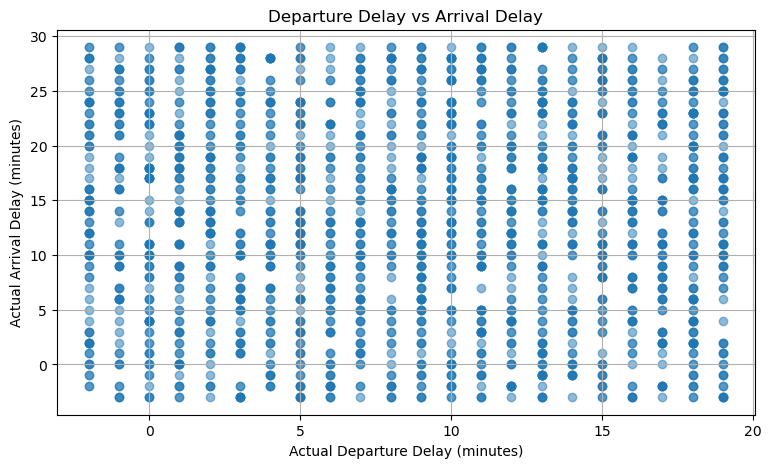

In [144]:

# STEP 7: Investigate departure delay vs arrival delay

import pandas as pd
import matplotlib.pyplot as plt

print("CORRELATION")
print(
    df["actual_departure_delay_min"].corr(
        df["actual_arrival_delay_min"]
    )
)

print("\nDEPARTURE DELAY SUMMARY")
display(
    df["actual_departure_delay_min"].describe()
)

print("\nARRIVAL DELAY SUMMARY")
display(
    df["actual_arrival_delay_min"].describe()
)

# Compare average arrival delay across departure-delay groups
df["departure_delay_group"] = pd.cut(
    df["actual_departure_delay_min"],
    bins=[-float("inf"), 0, 5, 10, 20, float("inf")],
    labels=[
        "Early/on time",
        "1–5 min",
        "6–10 min",
        "11–20 min",
        "Above 20 min"
    ]
)

print("\nARRIVAL DELAY BY DEPARTURE DELAY GROUP")
display(
    df.groupby(
        "departure_delay_group",
        observed=False
    )["actual_arrival_delay_min"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

plt.figure(figsize=(9, 5))
plt.scatter(
    df["actual_departure_delay_min"],
    df["actual_arrival_delay_min"],
    alpha=0.5
)
plt.xlabel("Actual Departure Delay (minutes)")
plt.ylabel("Actual Arrival Delay (minutes)")
plt.title("Departure Delay vs Arrival Delay")
plt.grid(True)
plt.show()


ARRIVAL DELAY VALUE COUNTS


,Frequency
actual_arrival_delay_min,
-3,55
-2,61
-1,49
0,55
1,50
2,57
3,55
4,62
5,57


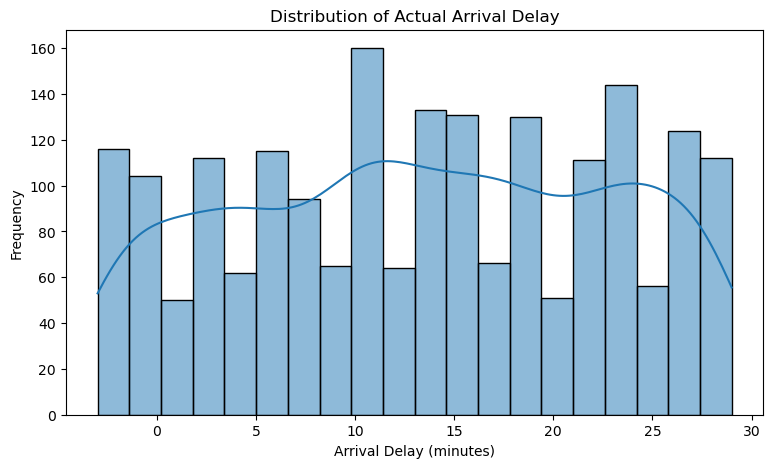


AVERAGE ARRIVAL DELAY BY TRANSPORT_TYPE


,count,mean,std
transport_type,,,
Train,493,13.55,9.16
Bus,525,13.54,9.24
Metro,491,13.21,9.65
Tram,491,12.95,9.12



AVERAGE ARRIVAL DELAY BY WEATHER_CONDITION


,count,mean,std
weather_condition,,,
Rain,321,13.62,9.49
Snow,343,13.53,9.18
Clear,343,13.50,9.15
Storm,337,13.29,9.33
Cloudy,325,13.07,9.23
Fog,331,12.88,9.41



AVERAGE ARRIVAL DELAY BY EVENT_TYPE


,count,mean,std
event_type,,,
Protest,86,13.90,9.23
Parade,105,13.62,8.98
NaN,1173,13.53,9.37
Concert,203,12.83,9.27
Sports,212,12.82,9.48
Festival,221,12.77,8.92



AVERAGE ARRIVAL DELAY BY SEASON


,count,mean,std
season,,,
Autumn,480,13.89,9.47
Spring,502,13.40,9.28
Winter,494,13.31,9.19
Summer,524,12.72,9.21



NUMERIC FEATURE CORRELATIONS


,Correlation
temperature_C,-0.0399
humidity_percent,-0.0277
traffic_congestion_index,-0.0110
wind_speed_kmh,-0.0076
precipitation_mm,0.0011
event_attendance_est,0.0373


In [145]:

# STEP 8: Check target distribution and feature relationships

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target frequency distribution
print("ARRIVAL DELAY VALUE COUNTS")
display(
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
    .to_frame("Frequency")
)

# 2. Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    df["actual_arrival_delay_min"],
    bins=20,
    kde=True
)
plt.title("Distribution of Actual Arrival Delay")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.show()

# 3. Compare target across important categorical features
features = [
    "transport_type",
    "weather_condition",
    "event_type",
    "season"
]

for feature in features:
    print(f"\nAVERAGE ARRIVAL DELAY BY {feature.upper()}")

    display(
        df.groupby(feature, dropna=False)[
            "actual_arrival_delay_min"
        ]
        .agg(["count", "mean", "std"])
        .round(2)
        .sort_values("mean", ascending=False)
    )

# 4. Compare target against numeric features
numeric_features = [
    "temperature_C",
    "humidity_percent",
    "wind_speed_kmh",
    "precipitation_mm",
    "event_attendance_est",
    "traffic_congestion_index"
]

correlations = (
    df[numeric_features + ["actual_arrival_delay_min"]]
    .corr(numeric_only=True)["actual_arrival_delay_min"]
    .drop("actual_arrival_delay_min")
    .sort_values()
)

print("\nNUMERIC FEATURE CORRELATIONS")
display(correlations.to_frame("Correlation").round(4))


In [146]:

# STEP 9: Check whether arrival delays are unusually uniform

import numpy as np
import pandas as pd
from scipy.stats import chisquare

# Frequency of each possible integer delay
observed = (
    df["actual_arrival_delay_min"]
    .value_counts()
    .reindex(range(-3, 30), fill_value=0)
    .sort_index()
)

# Expected frequency if all 33 integer values
# were equally likely
expected = np.full(
    len(observed),
    len(df) / len(observed)
)

chi_stat, p_value = chisquare(
    f_obs=observed.values,
    f_exp=expected
)

print("Number of unique delay values:", df["actual_arrival_delay_min"].nunique())
print("Minimum delay:", df["actual_arrival_delay_min"].min())
print("Maximum delay:", df["actual_arrival_delay_min"].max())
print("Chi-square statistic:", round(chi_stat, 4))
print("P-value:", round(p_value, 6))

print("\nFrequency standard deviation:")
print(round(observed.std(), 4))

print("\nFrequency mean:")
print(round(observed.mean(), 4))

display(observed.to_frame("Frequency"))


Number of unique delay values: 33
Minimum delay: -3
Maximum delay: 29
Chi-square statistic: 40.39
P-value: 0.146685

Frequency standard deviation:
8.7462

Frequency mean:
60.6061


,Frequency
actual_arrival_delay_min,
-3,55
-2,61
-1,49
0,55
1,50
2,57
3,55
4,62
5,57


In [147]:

# FINAL DATA QUALITY INVESTIGATION

print("DATASET DATE RANGE")
print("Start:", df["date"].min())
print("End:", df["date"].max())
print("Unique dates:", df["date"].nunique())

print("\nSEASON DISTRIBUTION")
display(df["season"].value_counts())

print("\nEVENT TYPE VS EVENT ATTENDANCE")
display(
    df.groupby(
        df["event_type"].isna(),
        dropna=False
    )["event_attendance_est"]
    .agg(["count", "mean", "min", "max"])
)

print("\nTARGET BY DATE")
daily = (
    df.groupby("date")["actual_arrival_delay_min"]
    .agg(["count", "mean", "std"])
)

display(daily.round(2))

print("\nTARGET BY ROUTE")
display(
    df.groupby("route_id")["actual_arrival_delay_min"]
    .agg(["count", "mean", "std"])
    .round(2)
)


DATASET DATE RANGE
Start: 2023-01-01
End: 2023-01-22
Unique dates: 22

SEASON DISTRIBUTION


season
Summer    524
Spring    502
Winter    494
Autumn    480
Name: count, dtype: int64


EVENT TYPE VS EVENT ATTENDANCE


,count,mean,min,max
event_type,,,,
False,827,6616.082225,0,50000
True,1173,6282.182438,0,50000



TARGET BY DATE


,count,mean,std
date,,,
2023-01-01,76,12.01,9.44
2023-01-02,96,15.00,8.72
2023-01-03,96,13.81,8.88
2023-01-04,96,13.92,8.70
2023-01-05,96,12.03,9.40
2023-01-06,96,14.49,9.34
2023-01-07,96,13.38,9.69
2023-01-08,96,13.75,8.79
2023-01-09,96,13.72,9.56



TARGET BY ROUTE


,count,mean,std
route_id,,,
Route_1,87,13.43,9.52
Route_10,86,11.81,8.99
Route_11,88,13.34,9.44
Route_12,105,14.29,8.49
Route_13,112,11.93,9.22
Route_14,105,13.50,9.24
Route_15,112,13.99,9.08
Route_16,80,13.16,9.87
Route_17,110,13.47,9.19
